Cell M6-1(markdown)|第 1 節:notebook 定位

### 06 | 挽留實驗設計(A/B 測試)(M6)

**目的**:<br/>
M0 至 M5 回答的問題是「誰會流失、為什麼、該對誰做什麼」;本模組回答的問題是「M5 設計的挽留動作,要怎麼驗證這個動作真的有用」。<br/>
M5 已證明命中 3+ 的客戶流失率 82.9%,但這只說明這群人風險高,沒有說明「對他們投放推播回饋之後,流失率會不會下降」。M3 第 10 節與 M5 第 9 節都寫明:本專案的證據只能證明關聯,不能證明因果。要知道動作有沒有效,唯一可靠的方法是隨機對照實驗(randomized controlled experiment),在業界通稱 A/B 測試(A/B test):把同一群客戶隨機分成兩組,一組收到動作、一組不收到,一段時間後比較兩組的流失率。<br/>

**支持的決策**:<br/>
問題定義書決策 3(提出可驗證的挽留方案)的後半:「方案是否有效」的驗證方法。M5 完成的是「方案內容」,本模組完成的是「驗證方案的實驗設計」。<br/>

**本模組與前五個模組最大的差別**:<br/>
前五個模組都是「拿既有資料算答案」;本模組是「寫一份還沒執行的計畫」。本資料集沒有任何「投放之後」的欄位,所以本模組做不出「實驗結果」,只能做出「實驗設計」,以及一套「結果回來之後立刻能跑」的分析程式。這一點在本 notebook、實驗計畫書與決策日誌都寫明,所有以模擬資料跑出的數字都標示為模擬,不是實驗結果。<br/>

**本模組的三個產出**:<br/>
1. `docs/06_experiment_plan.md`:實驗計畫書,給決策者與不看程式碼的讀者,兩到三頁,寫明對象、動作、指標、人數、期間、判定規則、風險。<br/>
2. 本 notebook(`notebooks/06_experiment_design.ipynb`):計畫書每個數字的計算依據與判讀,含分層隨機分組的程式、平衡檢查、以模擬資料跑通的分析模板。<br/>
3. `sql/05_experiment_population.sql`:從 clean.customers 重現 M5 的客戶層級表並圈出實驗母體、分層欄位與平衡檢查用變數。<br/>

**各節 Roadmap**:<br/>

| 節 | 目標 | 做法 | 實務效果 | 承接或定案的待驗證事項 |
|---|---|---|---|---|
| 1 | 說明本模組用到的概念 | 混淆、隨機分組、隨機化單位、假設、三層級指標、樣本數四要素、MDE 與成功率的換算、實驗期間、分層隨機、平衡檢查、分析計畫、意圖處理分析、模擬的定位 | 讀者能看懂後面每一節的判讀、理解概念 | — |
| 2 | 選定實驗母體 | 比較三個候選母體(搶救區命中 3+、低成本區命中 3+、低成本區命中 ≥2)的人數、歷史流失率、執行條件 | 第一個實驗選低成本區命中 3+(517 人);說明「歷史流失率」與「實驗期間流失率」的落差 | #28 |
| 3 | 寫下假設與指標 | 一個主指標決定成敗、兩個次要指標解釋機制、一個護欄指標防副作用;三條決策規則 | 只有一個決策指標,α 不校正;回答 #23 | #23 |
| 4 | 計算樣本數與期間 | 以 M3 第 8 節的方法(Cohen's h、α、檢定力 0.8)計算,畫 MDE 曲線,檢查母體是否足夠 | 每組需 390 人、合計 780 人,517 人的母體不足;全部納入時可靠偵測的最小效果為 10.3 個百分點(成功率 12.5%);記錄「規劃值每組 197 人為公式錯誤」的實作後修正,以及母體不足時的補救方式 | #23、#33 |
| 5 | 分層隨機分組與平衡檢查 | 以價值層與加碼觸發條件分層,固定隨機種子在每層內對半分;以標準化平均差檢查兩組是否平衡 | 十三個變數中十一個平衡、兩個略高於門檻,預註冊(preregistration)一項調整後的穩健性檢查(robustness check);記錄「四層改三層」的設計調整 | — |
| 6 | 分析計畫模板(模擬資料) | 依分層的歷史流失率產生一份模擬結果,把兩比例 z 檢定、信賴區間、次要與護欄指標、子群分析、代回 M5 公式的流程跑一次;以 1,000 次模擬驗證檢定力 | 證明分析程式在真實資料回來前已寫好且能跑;輸出表格就是未來報告的格式 | #28 |
| 7 | 風險清單與第二個實驗草案 | 五項常見風險的預防方式;「調高額度」實驗的草案(假設、候選母體、缺少的輸入) | 讓業務單位知道實驗可能會在哪裡出錯;#11 改列「待第二個實驗驗證」 | #11(M6 部分) |
| 8 | 結論、限制、待驗證事項清單 v7 | 收斂為一張實驗設計總表;#23、#28 結案;新增 #33 至 #36 | M7 可直接承接 | — |

**承接的待驗證事項**(notebook 05 Cell M5-18 清單 v6):<br/>
待驗證事項 #11(M6 部分):「調高額度」作為挽留手段須經隨機分組實驗驗證;#23:樣本數計算沿用 M3 第 8 節方法,若同時檢定多個指標以校正後 α 計算,分層隨機化時調整計算方式;#28:第一個實驗建議選搶救區或低成本區命中 3+ 客群,主指標為「投放後一季的流失率」,產出之一是「量出實際的挽留成功率」並「代回 notebook 05 第 6 節的公式」。<br/>

**不在本模組做的事(範圍界定)**:<br/>
(1) 不執行實驗、不產生真實結果;(2) 不做第二個實驗(調高額度)的完整設計,只寫草案(理由見第 7 節與決策日誌 [M6-4]);(3) 不做多組實驗(multi-arm test)或因子設計(factorial design),理由見第 1 節 1.5 與第 7 節;(4) 不對次要指標做正式檢定與 α 校正,理由見第 3 節。<br/>

**資料來源**:<br/>
`clean.customers` 資料表;「母體圈選」與「分層欄位」以 sql/05_experiment_population.sql 的查詢為準,本 notebook 以 pd.read_sql 執行相同查詢。「樣本數計算」使用 statsmodels(與 notebook 03 第 8 節相同);「隨機分組與模擬」使用 numpy,固定隨機種子。<br/>

**判讀格式**:沿用本案通用的四段格式:實測 / 判定 / 對決策的意涵 / 待辦或限制。<br/>

**執行原則**:commit 前一律 Restart & Run All;隨機分組與模擬固定 RANDOM_STATE = 42,使每次執行結果相同(可重現性);分組結果存成檔案(data/processed/06_experiment_assignment.csv),用途有二:執行推播的系統依此名單決定對誰推播、對誰發加碼版、對誰不推播;事後若有爭議(例如某位客戶抱怨未收到回饋),可查核該客戶被分到哪一組、處理是否與名單一致。<br/>

Cell M6-2(markdown)|概念說明

## 第 1 節|本模組使用的概念

本節每一個概念都依「定義 → 為什麼需要它 → 本案的設定」三段說明,是後面各節判讀的共同依據。M3 已定義過的統計名詞(α、檢定力、Cohen's h、兩比例 z 檢定、信賴區間)在 1.11 以一兩句重述,方便對照。<br/>

### 1.1 為什麼不能直接投放後看流失率有沒有降:混淆

若對全部命中 3+ 的客戶推播回饋方案,一季後流失率從 82.9% 降到 70%,分析者無法確定這是推播造成的。因為「同一季裡可能同時發生別的事」:銀行調整年費、競爭對手推出新卡、整體經濟環境改變。這些事情對所有客戶都有影響,分析者無法把「推播的效果」與「其他事情的效果」分開。這種情形稱為混淆(confounding):兩個以上的原因同時發生,結果「無法歸因給其中任何一個」。<br/>
解決方法是「在同一段時間裡,讓一部分客戶收到推播、另一部分不收到推播」。兩群客戶經歷了同樣的年費調整、同樣的經濟環境,唯一的差別是「有沒有收到推播」,所以兩群客戶流失率的差距只能歸因給推播。這就是對照(control)的意義。收到動作的那一群稱為實驗組(treatment group),沒收到動作的那一群稱為對照組(control group)。<br/>

### 1.2 為什麼分組一定要隨機:選擇偏誤

若由業務人員自行挑選誰收到推播,業務人員會傾向挑「看起來比較有希望留住」的客戶;收到推播的那群客戶本來就比較不會流失,最後就算這群客戶的流失率較低,也不是推播的功勞。這種「分組的方式本身就偏向某個結果」的情形稱為選擇偏誤(selection bias)。<br/>
隨機分組(randomization)的意思是:每位客戶被分到哪一組,由「一個與客戶本身無關的隨機程序」決定(本案用 numpy 的隨機數產生器)。隨機分組的效果是,所有分析者知道的特徵(年齡、交易金額)與不知道的特徵(客戶對銀行的印象、近期的家庭狀況)在兩組之間平均起來都會接近。只要人數足夠,兩組在實驗開始前就是「幾乎相同的兩群人」,之後出現的差異只能歸因給動作本身。<br/>
隨機分組是 A/B 測試與 M3、M4 觀察性分析最根本的差別:M3 的檢定與 M4 的模型都是在「沒有人介入」的資料上建立關聯;隨機分組讓分析者自己製造「只差一個條件(是否收到動作)」的兩群人,因此能推論「動作 → 流失率」的因果關係。程式與表格中以 arm 標示組別(treatment = 實驗組、control = 對照組),arm 是實驗設計通用的英文用語。<br/>

### 1.3 隨機化單位

隨機化單位(randomization unit)是「被隨機分配到某一組」的最小對象,例如:一位客戶、一個帳戶、一家分行、一個家庭。選擇單位要依據兩件事:第一,動作是對誰執行的:推播是發給個人,單位自然是「客戶」。第二,單位之間會不會互相影響:若同一個家庭的兩個人一個收到推播、一個沒收到,收到的人可能告訴另一個人,對照組就被實驗組的訊息影響,這種情形稱為干擾(interference)或溢出效應(spillover);遇到這種情形,實務上會「把單位放大到家庭或分行」,讓會互相影響的人都在同一組。<br/>
本案的隨機化單位是客戶(clientnum),原因是:推播回饋是個人化的,溢出風險低;而且資料集也沒有家庭或分行欄位。隨機化單位的選擇與理由寫進實驗計畫書,因為它決定了樣本數的計算單位與分析的獨立性假設。<br/>

### 1.4 假設

每個實驗只回答一個問題,這個問題要寫成「可以被資料推翻的句子」,寫法與 M3 相同:<br/>
- 虛無假設(null hypothesis, H0):推播對流失率沒有影響,實驗組與對照組一季內的真實流失率相同。<br/>
- 對立假設(alternative hypothesis, H1):兩組的真實流失率不同(本案預期實驗組的流失率較低)。<br/>
實驗結束後,以統計檢定判斷資料是否足以推翻 H0。若確實推翻了 H0,本案才能說「推播有效」。<br/>

### 1.5 指標:主指標、次要指標、護欄指標

**主指標(primary metric)**:實驗成敗只看這一個數字;樣本數是為了主指標而計算,只對主指標做正式檢定。本案的主指標是「投放後一季內的流失率」,訂定的原因有二:(1) M5 的目標是降低流失;(2) 流失是清楚的 0/1 事件,每位客戶在觀察期結束時只有「流失」或「未流失」兩種狀態,流失率 = 流失人數 ÷ 組內人數,任何人計算都得到同一個數字。相對地,交易金額這類指標的計算有歧義:退款是否扣除、極端大額消費如何處理、觀察期起訖如何切,不同人的算法不同。<br/>
**次要指標(secondary metrics)**:幫助解釋主指標「為什麼改變或不變」的數字。本案設兩個次要指標:一季內的「交易金額」與「交易筆數」。主指標只回答「推播有沒有讓客戶留下」,不回答「怎麼留下的」:若流失率沒有下降但交易金額上升,代表推播改變了消費行為、但不足以改變去留,下一個實驗可改測加碼幅度更大的版本;<br/>
若流失率下降、但實驗組的平均交易金額沒有相應上升,代表「新留住的客戶消費很低」(平均值包含流失者的 0,流失率下降後,有消費的人會變多,留住的人若有消費,平均值應上升。若沒有上升,代表新留住的人消費很低),M5「留住有價值的客戶」的目標沒有達成。(觀念推導:如果最後算出來的平均交易金額沒有上升(持平甚至下降),唯一的解釋就是:這些被新留住的用戶,他們貢獻的交易金額非常低(低到雖然不是 0,但微不足道,甚至拉低了原本消費主力拉高的平均值))。<br/>
次要指標不用來判定成敗。選這兩個指標的依據:交易金額是 M5 的價值軸(total_trans_amt);交易筆數是 M4 模型中對流失影響最大的變數(total_trans_ct,筆數越少越容易流失),筆數上升代表推播改善了最重要的風險訊號。<br/>
**護欄指標(guardrail metric)**:實驗不得使其惡化的數字。本案設一個護欄指標:「一季內的客服聯繫次數」。M2 的切片、M3 T1 的卡方檢定(Cramér's V 0.241)與 M4 模型 A(勝算比 4.4)都顯示高聯繫與流失強相關;若推播引發客戶抱怨,聯繫次數會上升;就算流失率下降,若護欄指標惡化超過本案設定的門檻,方案也不能上線。護欄指標不做顯著性檢定,只設「惡化不得超過多少」的門檻,原因是護欄回答的是「有沒有變壞到不能接受」這個業務容忍度的問題,不是「兩組是否不同」的統計問題;若改用檢定判定,人數大時連 0.1 次這種業務上可忽略的小幅上升也會顯著,若把護欄的判定規則寫成「護欄顯著 → 不上線」,只要推播讓聯繫次數有一點點上升(任何主動聯繫客戶的動作幾乎都會)、實驗就過不了護欄指標,每個實驗都會被護欄擋下、無法通過;**門檻要檢驗的是「上升幅度有沒有超過可承受範圍」,不是「有沒有上升」**。所以要用「門檻」,不是用「檢定」。<br/>
**為什麼要分層級而不是全部檢定**:每做一次檢定就有一次誤判的機會,α = 0.05 代表「動作其實沒效,卻有 5% 的機率被判成有效」。若對多個指標(三個指標:主指標、兩個次要指標)各做一次檢定,只要任何一個顯著就宣稱成功,整體誤判率會升到 1 − 0.95³ ≈ 14.3%。這就是 M3 第 2 節 2.4 的多重比較問題(multiple comparisons problem)。M3 的解法是用 Bonferroni 校正(把 α 除以檢定次數),代價是「樣本數變大」:α 從 0.05 降到 0.017 (0.05 ÷ 3) 後,同樣的差距要更難被判成碰巧,需要更小的抽樣波動,也就是更多人(第 4 節實測:390 人升為 521 人)。業界的標準做法是「只讓一個指標承擔決策角色」,其他指標只描述、不做正式檢定,這樣不需要校正,樣本數也不會膨脹。這是本模組回應「待驗證事項 #23」的方式:本實驗只有一個決策指標,α 維持 0.05 不校正;若未來「把次要指標升為決策指標」,再依 #23 以「校正後的 α」重算樣本數。<br/>

### 1.6 樣本數:要多少人才夠

**為什麼人數(樣本數)不夠會出問題**:假設推播真的能把流失率從 82.4% 降到 74.2%。若只找 20 位客戶做實驗,每組 10 人,對照組可能剛好 9 人流失、實驗組剛好 8 人流失,差距只有一個人,這個差距很可能是抽樣波動造成的,統計檢定會判定兩組「看不出差異」,分析者會因此錯誤地結論「推播沒用」。這種「動作有效,但實驗沒偵測到」的錯誤是 M3 定義的型二錯誤(Type II error)。<br/>

**決定樣本數的四個量(指標)**:<br/>
1. 基準率(baseline rate):對照組預期的流失率。本案以母體的歷史流失率當作規劃依據(命中 3+ 子群的流失率為 82.4%)。<br/>
2. 最小可偵測效果(minimum detectable effect, MDE):實驗至少要能偵測到多大的改善。MDE 不是「分析者猜推播有多大效果」,而是「若小於這個幅度的改善,就算測到了也不值得上線」。本案的 MDE 由 M5 第 6 節的成本效益試算反推,見下段。<br/>
3. 顯著水準 α:可允許的「型一錯誤率」,亦即「其實動作沒效,卻判定成有效」的機率。沿用 M3,設定 α = 0.05,雙尾(雙尾與單尾的差別見 1.9)。<br/>
4. 檢定力(statistical power,1 − β):「真的有效時,實驗能偵測到」的機率。沿用 M3 數字,設定檢定力為 0.8。<br/>

**MDE 與挽留成功率的換算(本案的重要觀念)**:<br/>
M5 的「挽留成功率」定義是「名單上本來會流失的人裡,被動作留住的比例」。母體的流失率是 82.4%,意思是 100 位客戶裡有 82 位本來會走;成功率 10% 的意思是這 82 位裡有 10%(約 8 位)被留下來,所以流失率會從 82.4% 降到 74.2% (82.4% × (1 − 0.10))  ,降幅約 8.2 個百分點。換算公式是:<br/>
**流失率降幅(百分點)= 基準流失率 × 挽留成功率**。<br/>
「成功率 10%」不等於「流失率降 10 個百分點」,兩者是不同的量;本模組的 MDE 設為 82.4% × 10% ≈ 8.2 個百分點,不是 10 個百分點。<br/>
**為什麼用 M5 最低的情境(10%)來反推 MDE**:M5 第 6 節把成功率設成 10%、20%、30% 三個情境,實驗的目的是量出真實的成功率,用一個實測數字取代這三個假設。若實驗連「成功率 10%」這麼小的效果都偵測不到,那麼實驗結果「沒有顯著差異」會同時與兩種情形相容:(1) 推播真的沒用(效果為 0);(2) 推播有用,但效果在 0 至 10% 之間,實驗的人數不足以偵測。資料無法區分這兩種情形,M5 的試算就得不到任何一個可代入的數字,三個情境仍停留在假設。因此 MDE 設在 M5 試算裡最小的情境,實驗才能回答「效果至少有沒有 10%」這個 M5 提出的問題。<br/>

**怎麼算出樣本數**:沿用 M3 第 8 節的方法,以 statsmodels 套件的 NormalIndPower 計算,它實作的是「兩個比例比較」的標準樣本數公式。計算的輸入是四個量(基準率、MDE、α、檢定力),輸出是每組人數;套件先把「基準率」與「基準率 − MDE」兩個比例的差距換算成 Cohen's h(一個與基準率高低無關的效果量尺度,h 越大代表差距越容易偵測,h = 0.2 屬小效果),再依 α 與檢定力算出人數。需要理解的只有三個方向:想偵測的差距越小,人數越多,而且差距縮為一半時人數約增為四倍(因為抽樣波動的大小與人數的平方根成反比);要求的檢定力越高或 α 越嚴,人數越多;兩組比較比「一組與固定數字比較」需要更多人,因為兩組各自有抽樣波動。本案 h ≈ 0.20,每組約 390 人、兩組合計約 780 人(實際數字由第 4 節程式算出)。本模組規劃階段以公式試算時誤用了「一組與固定數字比較」的公式,預估每組 197 人,實作時由程式揭露此問題,修正過程記在第 4 節 4.1 與決策日誌 [M6-3]。<br/>
「差距越小需要越多人」的依據:人數與 h² 成反比,h 大致與降幅成正比,所以降幅縮為一半、人數約增為四倍(第 4 節 MDE 曲線:8 個百分點 413 人、4 個百分點 1,543 人)。<br/>

**樣本數算出來之後要對照母體**:母體人數必須大於兩組(實驗組與對照組)合計的所需人數,而且要留餘裕(本案建議在所需人數之外再預留 10% 至 20%),因為母體裡總會有一些客戶在實驗期間無法納入,例如:聯絡方式失效、已經銷戶、拒收推播、資料異常。若母體人數不足,有兩個常見的處理方式:放寬 MDE(接受只能偵測較大的效果),或擴大母體(改用低成本區命中 ≥2 的 2,050 人,基準率降為 49.2%,樣本數必須重算)。實作順序是「先依業務需求決定 MDE → 算出人數 → 對照母體 → 不足再調整」,而不是「先看母體有多少人,再決定能測多小的效果」,因為實驗是為了回答業務問題,MDE 的設定來自業務問題,人數是為了回答問題而付出的代價;若反過來先看母體,實驗會變成「母體能測到什麼就測什麼」,測得到的最小效果可能大於業務上值得上線的門檻,結果不顯著時既不能說動作無效、也不能說它未達門檻,業務問題沒有被回答。實務上這兩個方向會來回調整幾次,第 4 節把「所需人數」與「母體不足時的各個選項」都算出來,並記錄本案最後的取捨(4.1)。<br/>

**歷史流失率與實驗期間流失率的落差**:本資料集的「流失」是已經發生的事,82.4% 是歷史數字:517 人中有 426 人在資料快照時已標記為流失(attrition_flag = 'Attrited Customer')。真正執行實驗時,母體只能是「當時仍為有效客戶」的人,因為已流失的客戶無法再被推播挽留;這些客戶一季內的流失率一定低於 82.4%,因為歷史率的分子是「所有已經走的人」,而實驗期間一季內會走的只是仍在客戶中的一部分。基準率偏低會讓同樣的成功率對應較小的降幅(降幅 = 基準率 × 成功率;例如基準 50% 時,成功率 10% 只對應 5 個百分點),兩組的差距越小,需要越多人才偵測得到(1.6「怎麼算出樣本數」:差距縮為一半,人數約增為四倍),最初規劃的樣本數可能不足。所以本模組把歷史率(82.4%)當作「規劃用的基準」,並寫明「實驗開始前,要用當期資料重算基準率與樣本數」(第 7 節風險 3、待驗證事項 #33)。<br/>

### 1.7 實驗期間與「不能偷看」

主指標是「一季內的流失率」,觀察期至少一季。理由有三:<br/>
(1)資料集的消費變化比(total_amt_chng_q4_q1)本身就以季為比較單位,一季是這份資料的自然時間尺度;<br/>
(2)觀察期若太短,會看不到流失(例如:客戶不會收到推播隔週就銷戶),觀察期若太長則累積越多其他因素的影響(例如:競爭對手推出新卡、整體經濟環境改變)、也會讓業務單位等太久;<br/>
(3)一季與銀行的業務週期(季報)一致。<br/>
**觀察期間還有一個規則:結果在一季結束後一次判讀,中途不判讀。**<br/>
原因:若推播其實沒效,每一週的實際數字仍會有隨機波動,有時實驗組的流失率碰巧在某一週低一點,有時候對照組碰巧低一點;α = 0.05 的意思是「只在結束時看一次,碰巧看起來顯著的機率是 5%」。若每週看一次、連看 12 週,而且只要有一週看起來顯著就停下來宣布成功,誤判的機率就不再是 5%,而是「12 次裡至少一次碰巧顯著」的機率,這個機率會遠大於 5%。每多看一次,就多一次誤判的機會。實務上稱為「偷看問題(peeking problem)」,預防方式是「在計畫書寫明判讀時點(本案:一季結束後一次判讀)」。<br/>

### 1.8 分層隨機與平衡檢查

**分層隨機(stratified randomization)**:先依「一個或幾個已知與結果相關的變數」把母體分成幾層,在每一層裡面各自隨機分成實驗組與對照組。作用是「確保兩組在這些變數上的比例相同」,避免「隨機分組後,實驗組碰巧多分到一些高風險客戶」的情形;單純隨機分組在人數大時通常也會平衡,但本案只分組一次,這一次仍可能因抽樣波動而使某些變數在兩組分配不均;分層能在事前保證分層變數在兩組的比例相同。分層只保證「分層變數本身的平衡」,其他變數仍要靠平衡檢查確認。<br/>

**本案的分層變數有兩個,都是 M5 已證明「與流失率相關的變數」**,依據如下:<br/>
(1) **價值層(低 / 中)**:M5 矩陣(notebook 05 Cell M5-4)顯示同樣命中 3+,低價值層流失率 85.19%(412 人)、中價值層流失率 71.43%(105 人),相差 13.8 個百分點;sql/05 [E3] 在本母體內實測,低價值層流失率 83.0% 至 92.6%、中價值層流失率 66.7% 至 71.6%。<br/>
(2) **額外回饋觸發條件(消費變化比是否小於 0.50)**:M5 第 5 節證明「流失率隨消費變化比連續上升」(0.40 至 0.60 每 0.05 一箱的流失率為 38% → 29% → 23% → 16%),低成本區內消費變化比 < 0.50 的 308 人流失率 72.40%,高於低成本區整體的流失率 49.2%(notebook 05 Cell M5-9、M5-10)。sql/05 [E3] 在本母體內實測,低價值層中「符合加碼條件的客戶」流失率 92.6%,高於低價值層中「不符合加碼條件的客戶」的流失率 83.0%。<br/>
(3) 分層變數在實作後由四層合併為「三層」,原因與代價見第 5 節 5.1。<br/>

**分層數的實務原則**:每一層的人數要足以對半分成兩組(實驗組與對照組),分層慣例是:每層至少 20 人左右;分層越多,每層人數越少,所以太細的分層反而讓每一層都難以平衡(因為該層總人數太少),實務上「分層數通常控制在三到六層」。某一層人數太少時,標準處理是「把該層併入最相近的層」(pooling small strata)。<br/>

**平衡檢查(balance check)**:分組之後,把兩組在幾個關鍵變數上的平均值列成表,確認兩組平均值的差距很小。本案使用「標準化平均差」(standardized mean difference, SMD):「兩組平均值的差」除以「兩組合併的標準差」。交易金額的差是「元」、聯繫次數的差是「次」,無法互相比較;各自除以自己的標準差後,得到的是「差了幾個標準差」,沒有單位,所有變數就能用同一條門檻判斷,慣例上 |SMD| < 0.1 視為平衡。<br/>
平衡檢查表是實驗開始前,「兩組可比性」的證明,實務上附在實驗計畫書裡,讓業務單位與審核者在實驗開始前就能確認「兩組是公平的」,實驗結束後的差距才有說服力。若某個變數不平衡,分析時可用統計方法調整:以本案為例,若實驗組的往來產品數平均較高,可用 M4 的邏輯斯迴歸,把「是否在實驗組」與「往來產品數」同時放進模型,模型算出的是「在往來產品數相同的條件下,實驗組的流失勝算是對照組的幾倍」,這樣推播的效果就不會與往來產品數的差異混在一起(第 5 節 5.2 實際採用此做法)。<br/>

### 1.9 分析計畫:預先註冊與意圖處理分析

本節說明實驗結束後的分析流程:(1) 以兩比例 z 檢定比較兩組流失率並報告信賴區間與勝算比(主指標);(2) 以描述統計呈現次要與護欄指標;(3) 依分層做子群分析;(4) 依第 3 節的決策規則判定;(5) 把實測成功率代回 M5 第 6 節的公式。以下先說明三個流程上的原則。<br/>

**預先註冊的分析計畫(pre-registered analysis plan)**:在資料回來之前就把分析方法寫定,目的是避免事後看到結果才挑一個「剛好顯著」的方法,這會讓結論不可信。<br/>
本案的分析方法:主指標用兩比例 z 檢定(與 M3 T2、T3 相同),雙尾,α = 0.05,同時報告兩組流失率差距的 95% 信賴區間;次要指標與護欄指標以描述統計與信賴區間呈現,標明探索性;子群分析(subgroup analysis)把「符合加碼條件」那一層單獨比較,標明探索性。寫三條「決策規則」(第 3 節)。<br/>

**雙尾與單尾**:雙尾檢定的對立假設是「兩組流失率不同」(實驗組可能較低、也可能較高);單尾檢定的對立假設只有「實驗組低於對照組」。單尾把 5% 的誤判容許額度全部放在「較低」那一側,同樣的差距更容易達到顯著,所需的樣本數較少(第 4 節實測:308 人對 390 人)。<br/>
本模組選擇雙尾檢定,理由是:(1) 雙尾較保守,若推播反而讓流失率上升(例如推播引起反感),雙尾檢定能偵測到,但單尾檢定的設計不檢視那一側,就不會報告此結果;(2) 與 M3 的兩比例 z 檢定一致(proportions_ztest 預設雙尾),同一專案的檢定規則一致,讀者不必在模組之間切換判讀方式,數字也可直接對照。<br/>

**意圖處理分析(intention-to-treat analysis, ITT)**:分析時依「被分到哪一組」分組,不是依「有沒有真的收到推播」分組。原因是推播發出之後會再發生一次篩選:隨機分組時兩組是可比的兩群人,但推播發出後,不是每位實驗組客戶都會真的收到:有人沒裝 App、有人關閉通知、有人電話號碼失效。能收到推播的,通常是還在用 App、還在接電話的人,也就是本來就比較活躍、比較不會流失的人。若只拿「真的收到推播的人」與對照組比,等於拿「實驗組裡較活躍的一部分」去比「對照組的全部」,收到推播的那群人流失率較低,可能只是因為他們本來就活躍,不是推播的效果;隨機分組所消除的選擇偏誤,會在「送達」這一步重新產生。<br/>
意圖處理分析比較的仍是「隨機分出來的兩群人」,選擇偏誤不會重新產生;代價是:測出來的效果是「對整個實驗組發推播」的平均效果,其中未收到推播的客戶效果為 0,所以這個平均值低於「真的收到推播的客戶」的效果。但這個較低的數字才是方案上線後實際可預期的效果,因為真正上線時也一定會有客戶收不到推播。<br/>
假設實驗組 257 人中只有 70% 收到推播,ITT 算出的差距是「對 257 人發推播」的平均效果,其中 30% 的人沒收到、效果是 0,所以平均值被拉低;但真正上線時也會有 30% 收不到,所以這個被拉低的數字才是上線後會看到的效果。舉例:若 ITT 差距 8 個百分點、送達率 70%,推算「真的收到的人」效果約 11 個百分點;**上線時若能把送達率提高到 90%,預期效果會接近 10 個百分點**。<br/>

### 1.10 模擬的定位

本資料集沒有實驗結果,第 6 節用程式「製造」一份結果。做法是讓程式對每位客戶依指定的機率隨機抽出 1(流失)或 0(未流失):對照組客戶的機率是所在分層的歷史流失率,例如該層歷史流失率 83%,就有 83% 的機率抽到 1;實驗組客戶以「歷史流失率 × (1 − 假設成功率)」為機率抽出 0 或 1,例如 83% × 0.9 = 74.7%。這樣每位客戶都有一個模擬的「一季後是否流失」,再把 1.9 的分析流程(z 檢定、次要與護欄指標、子群分析、決策規則、代回 M5 公式)從頭跑到尾。<br/>
**第 6 節的目的只有一個:證明「分析程式已寫定、能執行、輸出的表格就是未來報告的格式」**。模擬的數字不是實驗結果,所有輸出都標示「模擬」。唯一有推論意義的是「檢定力的交叉驗證」:假設推播真的有 10% 的效果,用程式重複「製造結果、跑檢定」1,000 次,數有幾次判定顯著;這個比例就是實際分組下的檢定力,拿來與 statsmodels 用公式算出的理論值比對,兩者一致代表「樣本數公式、分析程式、分組名單」三者互相吻合。本案兩者都約 0.63,低於慣例的 0.8,原因是每組 258 人低於所需的 390 人(第 4 節 4.1)。<br/>
(「單次模擬的數字不具推論意義」:那一次模擬的 p = 0.0057 是分析者自己設定 10% 效果後抽出來的,它不證明任何關於推播的事;有推論意義的只有 1,000 次的比例(它驗證檢定力))<br/>


### 1.11 M3 已定義的名詞

| 名詞 | 定義 | 出處 |
|---|---|---|
| 顯著水準 α | 事前訂定的門檻,p 值小於 α 就拒絕 H0;代表「動作其實沒效卻被判成有效」的容許機率,本案設定 α = 0.05 | notebook 03 第 2 節 2.1 |
| p 值 | 假設 H0 為真(推播沒效),碰巧觀察到「至少與本次實驗一樣大的兩組流失率差距」的機率;p 值越小,代表差距越不可能是碰巧 | notebook 03 第 2 節 2.1 |
| 檢定力 | 推播真的有效(效果至少等於 MDE)時,檢定能判定顯著的機率;慣例設為 0.8 | notebook 03 第 2 節 2.5 |
| Cohen's h | 把「兩組流失率的差距」換算成一個與基準率高低無關的效果量,h = 2 × (arcsin√p₁ − arcsin√p₂);Cohen's h 描述差距本身的大小,與有多少人無關(人數影響的是能不能偵測到它);是樣本數計算的輸入之一 | notebook 03 Cell M3-5 |
| 兩比例 z 檢定 | 比較實驗組與對照組的流失率是否不同:(兩組流失率的差)÷ 標準誤 = z;z 越大,p 越小 | notebook 03 T2、T3 |
| 95% 信賴區間 | 考慮抽樣波動後,「兩組真實流失率的差距」合理的數值範圍;若這個範圍不包含 0,代表「兩組其實相同」不在合理範圍內,與「p < 0.05」是同一個判斷,只是表達方式不同 | notebook 03 第 2 節 2.2 |
| 多重比較 / Bonferroni | 檢定次數越多,至少一次碰巧顯著的機率越高(偽陽性風險越高);Bonferroni 的做法是把 α 除以檢定次數作為每次檢定的新門檻,例如三個指標各檢定一次,門檻改為 0.05 ÷ 3 ≈ 0.017 | notebook 03 第 2 節 2.4 |
| 精確率 | 「名單內真的會流失的人」占「名單總人數」的比例 | notebook 02、04、05 |
| 挽留成功率 | 對「本來會流失的客戶」投放挽留動作後,因此留下來的比例;這是 M5 成本效益試算中唯一無法從歷史資料估計、且對結果影響最大的參數,只有實驗能測出 | notebook 05 第 1 節 1.5 |

### 1.12 理論對到本案:對照表

| 概念 | 本案的設定 | 依據 |
|---|---|---|
| 要驗證的動作 | M5 第 4 節低成本區的推播組合(推送分期零利率方案(建立持續往來) + 滿額回饋 + 推薦一項標準產品 + 高聯繫者客服優先);符合加碼觸發條件者收到「加碼版的滿額回饋」 | notebook 05 Cell M5-8、[M5-2] |
| 實驗母體 | 低成本區(命中 ≥2 × 中低價值)中,「命中 3+ 的客戶」,517 人,即 M5 優先順序第 3 列;命中恰為 2 的客戶(M5 第 4 列)不在本實驗內;母體不足時的備案為擴大至整個低成本區(命中 ≥2,2,050 人) | #28、第 2 節 |
| 隨機化單位 | 客戶(clientnum) | 1.3 |
| 分層變數 | 價值層 × 加碼觸發條件,實作後合併為三層 | 1.8、第 5 節 |
| 假設 | H0:兩組的一季流失率相同;H1:不同(預期實驗組流失率較低) | 1.4 |
| 主指標 | 投放後一季內的流失率 | #28 |
| 次要指標 | 投放後一季內交易金額、交易筆數(探索性) | M5 價值軸、M4 結論 2 |
| 護欄指標 | 投放後一季內客服聯繫次數(惡化門檻見第 3 節) | M3 T1、M4 模型 A |
| 基準率 | 母體歷史流失率 82.4%(規劃用的數值;實際開始實驗前,要以「當期資料」重算) | sql/05 [E1] |
| MDE | 82.4% × 10% ≈ 8.2 個百分點(對應 M5 最低情境的成功率(成功率 10% 的情境)) | 1.6、notebook 05 第 6 節 |
| α / 檢定力 | α = 0.05 ; 雙尾檢定 ; 單一決策指標不校正 / 檢定力設為 0.8 | #23、notebook 03 第 8 節 |
| 樣本數計算方法 | 以 statsmodels 套件的 NormalIndPower 計算兩比例比較的樣本數;輸入為基準率、MDE、α、檢定力,效果量以 Cohen's h 表示 | notebook 03 Cell M3-19 |
| 實驗期間 | 一季,結束後一次判讀 | 1.7 |
| 分析方法 | 兩比例 z 檢定(雙尾)+ 95% 信賴區間;意圖處理分析 | 1.9 |
| 實驗產出的用途 | 真實實驗結束後,以兩組的實際流失率算出實測成功率 s = (p_c − p_t) ÷ p_c,代回 notebook 05 第 6 節公式 1 與公式 3,使 M5 的三個情境收斂為一組數字(第 6 節以模擬資料算出的 s = 11.8% 只用來示範表格格式,不是測量值) | #28、第 6 節 |
| 本實驗不涵蓋的動作 | 調高信用額度:另開第二個實驗測其對流失率的效果,本模組只寫草案,不設計、不執行完整實驗 | #11、[M5-2]、第 7 節 |

In [1]:
# Cell M6-3(code)|環境設定 + 候選母體比較 + 實驗母體的分層(對應 sql/05_experiment_population.sql [E0]、[E1]、[E3]、[E3-補])
import sys
import pathlib
sys.path.append(str(pathlib.Path.cwd().parent))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.power import NormalIndPower
from src.db import get_engine

warnings.filterwarnings("ignore")
engine = get_engine()

# 本模組共用常數
RANDOM_STATE = 42          # 隨機分組與模擬的固定種子(確保結果可重現;同 M4、M5)
ALPHA = 0.05               # 顯著水準,雙尾;單一決策指標不校正(第 1 節 1.5、待驗證事項 #23)
POWER = 0.80               # 目標檢定力(notebook 03 第 2 節 2.5 的慣例值)
SUCCESS_RATE_MIN = 0.10    # M5 第 6 節三個情境(10% / 20% / 30%)中最低的挽留成功率(10%),用來反推 MDE(第 1 節 1.6)
BUFFER = 0.15              # 母體餘裕:所需樣本數之外再預留 15%,涵蓋「聯絡失效、銷戶、拒收推播」等無法納入實驗的客戶(第 1 節 1.6)

# [E0] m6_base 的定義,以 CTE 形式供本 notebook 各查詢共用(欄位定義與 SQL 檔的暫存檢視表相同;完整表為 10,127 rows、22 欄,排序由各查詢的 ORDER BY 決定)(因為 CTE 本身沒有排序,各查詢如何排序應以其自身的 ORDER BY 設定來決定) (notebook 用 CTE 寫法、SQL 檔用 CREATE TEMP VIEW。兩者功能相同,但語法不同)
M6_BASE_SQL = """
WITH flags AS (
    SELECT clientnum, is_churned,
           (total_trans_ct <= 61)::int           AS low_activity,
           (avg_utilization_ratio = 0)::int       AS zero_util,
           (total_relationship_count <= 2)::int   AS shallow_rel,
           (contacts_count_12_mon >= 4)::int      AS high_contact,
           total_trans_amt, total_trans_ct, total_revolving_bal, total_relationship_count,
           contacts_count_12_mon, months_inactive_12_mon, total_amt_chng_q4_q1, total_ct_chng_q4_q1,
           customer_age, gender, credit_limit
    FROM clean.customers
),
scored AS (
    SELECT *,
           low_activity + zero_util + shallow_rel + high_contact AS hit_count,
           NTILE(3) OVER (ORDER BY total_trans_amt, clientnum)   AS value_tier
    FROM flags
),
zoned AS (
    SELECT *,
           CASE WHEN hit_count >= 3 THEN '3+' ELSE hit_count::text END AS risk_tier,
           CASE WHEN hit_count >= 2 AND value_tier = 3 THEN '1_rescue'
                WHEN hit_count >= 2                    THEN '2_low_cost'
                WHEN value_tier = 3                    THEN '3_deepen'
                ELSE                                        '4_monitor' END AS zone
    FROM scored
),
m6_base AS (
    SELECT clientnum, is_churned, value_tier, risk_tier, zone, hit_count,
           low_activity, zero_util, shallow_rel, high_contact,
           (zone = '2_low_cost' AND total_amt_chng_q4_q1 < 0.50)::int AS extra_reward,
           total_trans_amt, total_trans_ct, total_revolving_bal, total_relationship_count,
           contacts_count_12_mon, months_inactive_12_mon, total_amt_chng_q4_q1, total_ct_chng_q4_q1,
           customer_age, gender, credit_limit
    FROM zoned
)
"""

# [E1] 三個候選母體:人數、流失者、歷史流失率、平均年消費、符合加碼回饋條件的人數、規劃用的 MDE(= 歷史流失率 × 10%)
candidates = pd.read_sql(M6_BASE_SQL + """
SELECT '1_rescue_hit3plus' AS population, COUNT(*) AS n, SUM(is_churned::int) AS churners,
       ROUND(100.0 * AVG(is_churned::int), 1) AS churn_pct, ROUND(AVG(total_trans_amt)::numeric, 0) AS avg_trans_amt,
       SUM(extra_reward) AS extra_reward_n, ROUND(100.0 * AVG(is_churned::int) * 0.10, 1) AS mde_pp
FROM m6_base WHERE zone = '1_rescue' AND hit_count >= 3
UNION ALL
SELECT '2_low_cost_hit3plus', COUNT(*), SUM(is_churned::int), ROUND(100.0 * AVG(is_churned::int), 1),
       ROUND(AVG(total_trans_amt)::numeric, 0), SUM(extra_reward), ROUND(100.0 * AVG(is_churned::int) * 0.10, 1)
FROM m6_base WHERE zone = '2_low_cost' AND hit_count >= 3
UNION ALL
SELECT '2_low_cost_hit2plus', COUNT(*), SUM(is_churned::int), ROUND(100.0 * AVG(is_churned::int), 1),
       ROUND(AVG(total_trans_amt)::numeric, 0), SUM(extra_reward), ROUND(100.0 * AVG(is_churned::int) * 0.10, 1)
FROM m6_base WHERE zone = '2_low_cost' AND hit_count >= 2
""", engine)
assert candidates.loc[1, "n"] == 517 and candidates.loc[1, "churners"] == 426, "預設母體應為 517 人、426 位流失者(M5 矩陣 3+ × 低 + 3+ × 中)"
display(candidates)

# [E3]、[E3-補] 四個分層(價值層 × 加碼觸發條件)的人數與歷史流失率:「預設母體(命中 3+)」與「擴大母體(命中 ≥2)」
#     設計時規劃為四層;本表即顯示 mid_reward 僅 3 人,因此 Cell M6-8 依「每層至少 20 人」的規則合併為三層(第 5 節 5.1)
def strata_table(min_hits: int) -> pd.DataFrame:
    return pd.read_sql(M6_BASE_SQL + f"""
    SELECT stratum, COUNT(*) AS n, SUM(is_churned::int) AS churners,
           ROUND(100.0 * AVG(is_churned::int), 1) AS churn_pct,
           ROUND(AVG(total_trans_amt)::numeric, 0) AS avg_trans_amt,
           ROUND(AVG(total_trans_ct)::numeric, 1) AS avg_trans_ct,
           ROUND(AVG(contacts_count_12_mon)::numeric, 2) AS avg_contacts
    FROM (
        SELECT *, CASE WHEN value_tier = 1 THEN 'low' ELSE 'mid' END || '_' ||
                  CASE WHEN extra_reward = 1 THEN 'reward' ELSE 'base' END AS stratum
        FROM m6_base WHERE zone = '2_low_cost' AND hit_count >= {min_hits}
    ) AS pop
    GROUP BY stratum ORDER BY stratum
    """, engine)

strata_default = strata_table(3)
strata_expanded = strata_table(2)
assert strata_default["n"].sum() == 517 and strata_expanded["n"].sum() == 2050
print("預設母體(低成本區命中 3+)的四個分層:")
display(strata_default)
print("擴大母體(低成本區命中 ≥2)的四個分層:")
display(strata_expanded)

# 規劃用的基準率(母體歷史流失率)與 MDE(第 4 節使用);以 pandas 直接算,不依賴 SQL 的四捨五入
BASELINE = float(candidates.loc[1, "churners"] / candidates.loc[1, "n"])         # 0.824,基準率 = 對照組預期的流失率
MDE_ABS = BASELINE * SUCCESS_RATE_MIN                    # 0.0824,MDE = 基準率 × 成功率 10% = 流失率降幅 8.2 個百分點
TARGET = BASELINE - MDE_ABS      # 0.742,目標流失率 = 效果剛好等於 MDE 時實驗組的流失率;套件以它與基準率的差距算樣本數,不是業務目標
print(f"規劃用基準率 = {BASELINE:.4f};MDE = 基準率 × {SUCCESS_RATE_MIN:.0%} = {MDE_ABS:.4f}(即 {100*MDE_ABS:.1f} 個百分點);實驗組目標流失率 = {TARGET:.4f}")

,population,n,churners,churn_pct,avg_trans_amt,extra_reward_n,mde_pp
0,1_rescue_hit3plus,50,44,88.0,6520.0,0,8.8
1,2_low_cost_hit3plus,517,426,82.4,2076.0,98,8.2
2,2_low_cost_hit2plus,2050,1008,49.2,2202.0,308,4.9


預設母體(低成本區命中 3+)的四個分層:


,stratum,n,churners,churn_pct,avg_trans_amt,avg_trans_ct,avg_contacts
0,low_base,317,263,83.0,1902.0,39.2,3.75
1,low_reward,95,88,92.6,1650.0,36.1,3.73
2,mid_base,102,73,71.6,2967.0,48.8,3.56
3,mid_reward,3,2,66.7,3697.0,51.3,4.00


擴大母體(低成本區命中 ≥2)的四個分層:


,stratum,n,churners,churn_pct,avg_trans_amt,avg_trans_ct,avg_contacts
0,low_base,1210,597,49.3,1845.0,39.3,3.23
1,low_reward,295,219,74.2,1673.0,37.2,3.26
2,mid_base,532,188,35.3,3266.0,56.6,3.29
3,mid_reward,13,4,30.8,3862.0,62.5,3.38


規劃用基準率 = 0.8240;MDE = 基準率 × 10% = 0.0824(即 8.2 個百分點);實驗組目標流失率 = 0.7416


Cell M6-4(markdown)|第 2 節:實驗母體的選定與判讀

## 第 2 節|實驗母體(待驗證事項 #28;決策日誌 [M6-0])

### 2.1 三個候選母體

M5 Cell M5-18 建議第一個實驗選「搶救區或低成本區的命中 3+ 客群」。Cell M6-3 的 candidates 表列出兩者,再加上一個備案(擴大母體:低成本區命中 ≥2),三者的人數與歷史流失率都取自 M5 矩陣:搶救區命中 3+ 是「3+ × 高」格的 50 人,低成本區命中 3+ 是「3+ × 低」412 人與「3+ × 中」105 人的合計 517 人,低成本區命中 ≥2 是整個低成本區 2,050 人。<br/>

### 2.2 判讀

**實測**:<br/>
(1) 搶救區命中 3+:50 人、流失者 44 人、歷史流失率 88.0%、平均年消費 6,520 元;動作型態為人工聯繫(M5 第 4 節)。<br/>
(2) 低成本區命中 3+:517 人、流失者 426 人、歷史流失率 82.4%、平均年消費 2,076 元;其中符合加碼觸發條件者 98 人(占 19.0% :這個母體(517人)有 19.0% 的客戶(98 人)會收到加碼版);動作型態為自動化推播。<br/>
(3) 低成本區命中 ≥2:2,050 人、流失者 1,008 人、歷史流失率 49.2%、平均年消費 2,202 元;其中符合加碼觸發條件者 308 人(占 15.0% :這個母體(2,050人)有 15.0% 的客戶(308 人)會收到加碼版);動作型態為自動化推播。<br/>
(4) 規劃用 MDE(歷史流失率 × 10%):「搶救區命中 3+」為 8.8、「低成本區命中 3+」為 8.2、「低成本區命中 ≥2」為 4.9 個百分點。<br/>


**判定:第一個實驗的母體選「低成本區命中 3+(517 人)」;搶救區不作為第一個實驗的對象,理由如下**:<br/>
(1) **人數**:搶救區命中 3+ 只有 50 人,分成兩組後每組 25 人;依第 4 節的方法,25 人一組只能偵測到流失率下降約 34 個百分點(成功率約 39%)的效果,較小的真實效果都會被判成「沒有差異」。低成本區命中 3+ 有 517 人,每組約 258 人,在檢定力 0.8 下可偵測的最小效果為 10.3 個百分點(成功率 12.5%;「檢定力 0.8 下可偵測」的意思是效果真有這麼大時,十次實驗約有八次能判定顯著);雖然仍偵測不到規劃的 8.2 個百分點(第 4 節實測),但已是三個候選母體中最接近的一個,且不足的部分有明確的補救方式(第 4 節 4.1)。<br/>
(2) **執行的一致性**:搶救區的動作是人工聯繫,每位客戶經理的話術、態度、聯繫時間都不同,實驗組與對照組這兩組的差異會混入「由誰聯繫」這個變數,分析時難以分離;低成本區的動作是自動化推播,每位客戶收到的內容完全一致,兩組之間唯一的差別就是「有沒有收到推播」,因果歸因乾淨。<br/>
(3) **保留對照組的成本(the cost of holding out a control group)**:對照組要「刻意不聯繫」,業務單位通常不願意刻意不聯繫「最有價值的高風險客戶」,因為客戶越值錢、不聯繫的機會成本越高;搶救區客戶平均年消費 7,930 元,業務單位通常不願意對他們保留對照組;低成本區每人投放成本低(M5 第 3 節試算推播每人 5 元),而且對照組不投放(刻意不推播)的機會成本較小,業務單位比較容易同意。<br/>

**實務上的通則**:第一個挽留實驗幾乎都選「人數多、通路自動化、單位成本低」的客群,因為第一個實驗的目的不是立刻取得最大的金額效益,而是把實驗流程本身跑通:確認「隨機分組、資料回收(實驗結束後,從執行系統取得兩組客戶在觀察期內的流失、交易與聯繫紀錄;本模組無真實資料,此步驟不在本 notebook 內,第 6 節以模擬值示範其後的指標計算)、指標計算」都沒有問題,得出一個可信的成功率,再把這個實驗方法複製到高價值客群。如果用高價值客群做第一個實驗,一旦設計或執行出錯,損失的是最值錢的客戶,而且小樣本的結果較不可信。<br/>


**對決策的意涵**:<br/>
(1) **實驗母體定為「低成本區且命中 3+」的 517 人**(clean.customers 中 zone = '2_low_cost' 且 hit_count >= 3),即 M5 矩陣的「3+ × 低」與「3+ × 中」兩格;名單條件可直接寫成 SQL,業務單位可自行重算。<br/>
(2) 母體內部的組成(strata_default 表):低價值層 412 人(79.7%)、中價值層 105 人;符合加碼回饋條件者 98 人,其中低價值層 95 人、中價值層 3 人。低價值層內,符合加碼條件客戶的歷史流失率 92.6% 高於不符合者的 83.0%,與 M5 第 5 節「消費變化比越低,流失率越高」的方向一致;中價值層內符合加碼條件的客戶只有 3 人,3 人中 2 人流失(流失率 66.7%),人數太少,多一人或少一人流失就會變成 33.3% 或 100%,此流失率沒有判讀意義。四層過去 12 個月的平均客服聯繫次數在 3.6 至 4.0 次之間,彼此相近,代表兩組在護欄指標(定義見第 3 節 3.2)上的起點相同(sql/05 [E3] 計算得出)。<br/>
(3) 不是放棄對搶救區進行實驗,而是把「對搶救區的實驗」列為第二階段實驗:待第一個實驗測出成功率後,以實測的成功率作為效果大小的依據,回推搶救區實驗需要的人數(第 8 節限制、待驗證事項 #34)。<br/>
(4) 擴大母體(2,050 人)是第 4 節母體不足時的替代方案;其歷史流失率 49.2% 是預設母體 82.4% 的六成,同樣 10% 的成功率只對應 4.9 個百分點的降幅,需要的樣本數會明顯增加(第 4 節實測)。<br/>


**待辦或限制**:<br/>
(1) 本節的流失率是歷史數字:517 人中 426 人在資料快照時已標記為流失(attrition_flag = 'Attrited Customer')。真正執行實驗時,母體是「當時仍為有效客戶(attrition_flag = 'Existing Customer')、且特徵符合這兩格」的客戶,因為已流失的客戶無法再被挽留;他們一季內的流失率必然低於 82.4%,所以實驗開始前須以當期資料重算基準率與樣本數(第 1 節 1.6、第 7 節風險 3、待驗證事項 #33)。sql/05 [E2] 在實際執行時要加上 attrition_flag = 'Existing Customer' 的條件;本模組不對快照加這個條件,因為快照裡符合條件的只有 91 人且全部未流失,無法作為規劃依據,快照是一個時間點的照片,沒有「未來一季」的資料。<br/>
詳細解釋:<br/>
本資料集有 attrition_flag 欄位(Existing / Attrited),cleaning.py 據此建立 is_churned。517 人裡有 426 人在快照時已經是 Attrited, 82.4% 就是這樣算出來的。真正執行實驗那一天,母體只能是「當天仍為 Existing、且命中 3+」的客戶,因為已流失的人沒辦法再被推播挽留,所以 [E2] 的 WHERE 要加 attrition_flag = 'Existing Customer'。但這個條件不能套在本快照上,因為套上去只剩 91 人、流失率 0%(他們都還在),沒有任何規劃意義;快照是一個時間點的照片,實驗要的是「未來一季的流失」,本資料集沒有這個未來。所以本模組用歷史率當規劃基準,並寫明實驗前重算。<br/>
基準率「必然偏低」的原因:歷史率 82.4% 的分母包含「已流失者」,分子也是他們;**實驗期間的母體全部是還在的人**,**一季內會走的只是其中一部分**,所以一季流失率一定低於 82.4%。基準率低 → 同樣成功率對應的降幅變小(降幅 = 基準率 × 成功率)→ 差距變小 → 需要更多樣本數(人)。<br/>

(2) 本案資料集的「交易金額」對中途流失客戶有系統性低估(M5 第 9 節限制 1)(低成本區客戶自然也有這種情形),部分應屬搶救區的客戶可能在本實驗母體內;本模組不處理這個問題,因為實驗測的是「對這 517 人推播有沒有效」,母體的定義本身不受此偏差影響。<br/>

Cell M6-5(markdown)|第 3 節:假設、指標與決策規則

## 第 3 節|假設、指標與決策規則(待驗證事項 #23;決策日誌 [M6-1])

### 3.1 假設

- H0 (虛無假設 null hypothesis):實驗組與對照組一季內的真實流失率相同;推播對流失率沒有影響。<br/>
- H1 (對立假設 alternative hypothesis):兩組的真實流失率不同;推播降低流失率,本案預期實驗組的流失率較低。<br/>
檢定方法:兩比例 z 檢定(雙尾,α = 0.05),與 M3 T2、T3 相同;同時一併報告「流失率差距的 95% 信賴區間與勝算比」。選雙尾的理由見第 1 節 1.9。<br/>

### 3.2 指標表

| 層級 | 指標 | 定義與計算方式 | 角色 | 判定方式 |
|---|---|---|---|---|
| 主指標 | 一季內流失率 | 該組在觀察期內銷戶(或轉為 attrited)的客戶數 ÷ 該組人數;依意圖處理分析,以分組名單為分母,不扣除未收到推播者 | 唯一的決策指標;樣本數是為了主指標而計算 | 兩比例 z 檢定,若結果是 p < 0.05 且實驗組流失率較低 → 統計顯著,代表差距不太可能由抽樣波動造成;同時看兩組流失率的差距是否達到 MDE 8.2 個百分點:顯著回答「有沒有效」,差距大小回答「效果是否達到值得上線的門檻」;若顯著但差距未達 MDE,上線與否交由「代回 M5 公式後的成本效益」判斷 |
| 次要指標 1 | 一季內平均交易金額 | 該組客戶在觀察期內的交易金額總和 ÷ 該組人數;流失前的交易照算,流失後至季末沒有交易,計為 0,使每位客戶都有一個值、分母與主指標一致(本模組的模擬把流失者整季設為 0,見 Cell M6-10 步驟 1;這是模擬的簡化,可接受,因為這兩個指標的模擬值只用於示範格式) | 解釋機制:主指標只回答「有沒有留住」,此指標回答「留下來的客戶是否還有消費」 | 描述統計 + 95% 信賴區間;不做正式檢定;標明探索性 |
| 次要指標 2 | 一季內平均交易筆數 | 同上,以筆數計 | 解釋機制:交易筆數是 M4 模型中對流失影響最大的變數(筆數越少越容易流失),此指標回答「推播是否改善了最重要的風險訊號」 | 同上 |
| 護欄指標 | 一季內平均客服聯繫次數 | 該組客戶在觀察期內的聯繫次數總和 ÷ 該組人數 | 防止副作用:推播若引發抱怨會反映在此指標 | 實驗組的平均聯繫次數不得高於對照組平均的 1.2 倍(即上升不得超過兩成);超過即不上線。1.2 倍是本模組自訂的容忍門檻(1.2 倍的訂法:每組 258 人時,兩組平均值因抽樣波動的差異約在 ±5% 以內,門檻取 +20% 明顯高於波動,可避免把隨機差異誤判為惡化(護欄門檻沒有通用標準值,實務上由指標的負責單位依可承受的惡化幅度決定,商業實務上通常會將護欄指標的惡化容忍度定在(相對上升) 10% 至 20%;本案取 20%,約為兩組平均值抽樣波動(每組 258 人時約 ±5%)的四倍,不會被隨機差異觸發,且是容易說明的整數),且仍在客服人力可吸收的範圍;此為本模組自訂的起始值,計畫書標明「待客服單位確認」)(門檻的訂定原則:門檻要高於抽樣波動、又要在業務可吸收範圍) |
| 子群分析 | 主指標在各分層內的差距 | 分別對 low_base、low_reward、mid 三層計算該層內兩組的流失率差距 | 探索性:收到加碼版的那一層(low_reward)效果是否較大 | 只呈現各層的差距與 95% 信賴區間,不做檢定、不據此決策。原因有二:每層只有 95 (low_reward)至 317 人(low_base),差距的信賴區間很寬(例如模擬結果 low_reward 層的區間為 −25.4 至 +3.7 個百分點),無法確定方向;三層各比較一次等於三次檢定,碰巧顯著的機會增加(第 1 節 1.5 的多重比較)。子群的發現只用來寫成下一個實驗的假設,例如「加碼版那一層差距較大 → 下一個實驗測加碼幅度」 |

護欄門檻 1.2 倍是本模組自訂的操作慣例(與 [M2-10]、[M5-2] 的 50% 都是自訂的操作慣例,都是「沒有通用標準、由分析者自訂並標明待確認」,但兩者的訂定依據不同):母體的平均聯繫次數約 3.7 次,1.2 倍即約 4.4 次,恰好跨過高聯繫旗標的 4 次門檻,若推播讓實驗組的平均聯繫越過這條線,代表推播把客戶推向了本案定義的高風險行為;門檻可依業務單位的客服容量調整。<br/>

### 3.3 為什麼只有一個決策指標、α 不校正(回應 #23)

待驗證事項 #23 要求「若同時檢定多個指標,以校正後 α 計算樣本數」。本模組的做法是不讓這個條件發生:四個指標裡只有主指標承擔決策角色、做正式檢定,次要指標與護欄指標只描述、不檢定,因此檢定次數為一,α 維持 0.05,樣本數不須因校正而膨脹。<br/>
若把主指標與兩個次要指標都列為正式檢定,依 M3 的 Bonferroni 校正,α 變成 0.05 ÷ 3 ≈ 0.0167,樣本數會上升(M3 第 8 節的 H8 例子:門檻由 0.05 改為 0.0125,所需人數由 2,799 升至 3,977);而且實務上沒有人這樣做,因為上線決策從來不會因為「交易金額顯著」而改變。這是把 M3 學到的多重比較觀念用在實驗設計上的方式:不是每個指標都校正,而是先決定哪個指標才需要檢定。<br/>

### 3.4 三條決策規則(實驗結束後依此判定,不另外加條件)

1. 主指標顯著(p < 0.05 且實驗組流失率較低)且護欄指標未惡化 → 方案上線,並把實測成功率代回 notebook 05 第 6 節的公式(第 6 節示範)。<br/>
2. 主指標不顯著 → 方案不上線;次要指標與子群分析的發現寫成下一個實驗的假設,不作為上線依據。實務上遇到「次要指標顯著但主指標不顯著怎麼辦」的情形時,通常這樣處理。<br/>
3. 主指標顯著但護欄指標惡化(實驗組聯繫次數超過對照組的 1.2 倍)→ 方案不上線,先修改動作內容(例如推播頻率或文案)後再實驗。<br/>

### 3.5 本節對 M5 的回應

M5 第 6 節把挽留成功率設成三個情境,並寫明「M6 實驗的目標是測出實際的挽留成功率」。本實驗測出的量是兩組流失率的差距 Δ(對照組流失率 p_c 減實驗組流失率 p_t);依第 1 節 1.6 的換算,挽留成功率 s = Δ ÷ p_c。第 6 節示範把 s 代回公式 1(預期留住人數 = 名單內流失者 × s)與公式 3(每留住一人的成本 = 1 ÷(精確率 × s)),三個情境即收斂為一組數字。<br/>

預設母體:基準率 82.4% → 目標 74.2%(MDE 8.2 pp);Cohen's h = 0.201
每組所需人數 = 390、兩組合計 = 780;加 15% 餘裕後 = 897;母體 517 人 → 不足,尚缺 380 人(-42%)
若 517 人全部納入(每組 258 人):可偵測的 MDE = 10.3 pp,對應挽留成功率 12.5%


,mde_pp,success_rate_pct,n_per_arm,n_total
0,4.0,4.9,1543,3086
1,5.0,6.1,1005,2010
2,6.0,7.3,710,1420
3,7.0,8.5,531,1062
4,8.0,9.7,413,826
5,8.5,10.3,368,736
6,10.0,12.1,272,544
7,12.0,14.6,194,388
8,14.0,17.0,146,292
9,16.0,19.4,115,230


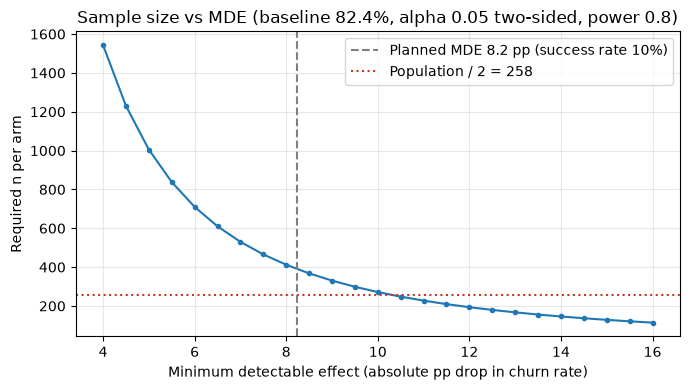

擴大母體:基準率 49.2% → MDE 4.9 pp;h = 0.099;每組 1615 人、合計 3230;母體 2050 人 → 不足
對照:單尾檢定下預設母體每組所需人數 = 308(雙尾 390);本案採雙尾
對照:三個指標皆正式檢定、Bonferroni 校正後每組所需人數 = 521(不校正 390)


In [2]:
# Cell M6-6(code)|第 4 節資料:樣本數、MDE 曲線、母體是否足夠、擴大母體的替代計算(方法同 notebook 03 Cell M3-19);本 cell 的輸出顯示 517 人不足,判讀與設計調整見 Cell M6-7 的 4.1
power_calc = NormalIndPower()

# 1. 預設母體:基準 82.4%、MDE = 基準 × 10%,Cohen's h 與每組所需人數(兩組人數相同,ratio = 1;雙尾 α = 0.05;檢定力 0.8)
h_default = proportion_effectsize(BASELINE, TARGET)            # 基準在前、目標在後,h 為正值;樣本數只看絕對值
n_per_arm = int(np.ceil(power_calc.solve_power(effect_size=h_default, power=POWER, alpha=ALPHA, ratio=1)))
n_total = 2 * n_per_arm
n_with_buffer = int(np.ceil(n_total * (1 + BUFFER)))
pop_default = int(candidates.loc[1, "n"])
print(f"預設母體:基準率 {BASELINE:.1%} → 目標 {TARGET:.1%}(MDE {100*MDE_ABS:.1f} pp);Cohen's h = {h_default:.3f}")
shortfall = pop_default - n_with_buffer
print(f"每組所需人數 = {n_per_arm}、兩組合計 = {n_total};加 {BUFFER:.0%} 餘裕後 = {n_with_buffer};母體 {pop_default} 人 → "
      + (f"足夠,餘裕 {shortfall} 人" if shortfall >= 0 else f"不足,尚缺 {-shortfall} 人({100*shortfall/n_with_buffer:.0f}%)"))

# 2. 反向計算:若把 517 人全部納入(每組約 258 人),能偵測到多小的效果(MDE)
n_half = pop_default // 2
h_detectable = power_calc.solve_power(nobs1=n_half, power=POWER, alpha=ALPHA, ratio=1)
# 由 h 反推實驗組流失率:h = 2·asin(√p1) − 2·asin(√p2) → p2 = sin(asin(√p1) − h/2)²
p2_detectable = np.sin(np.arcsin(np.sqrt(BASELINE)) - h_detectable / 2) ** 2
mde_detectable = BASELINE - p2_detectable
print(f"若 517 人全部納入(每組 {n_half} 人):可偵測的 MDE = {100*mde_detectable:.1f} pp,對應挽留成功率 {mde_detectable/BASELINE:.1%}")

# 3. MDE 曲線:MDE 從 4 到 16 個百分點,每組需要多少人(供決策者看「想偵測越小的效果,要付出多少人數」)
mde_grid = np.arange(0.04, 0.165, 0.005)
n_grid = [power_calc.solve_power(effect_size=proportion_effectsize(BASELINE, BASELINE - m), power=POWER, alpha=ALPHA, ratio=1) for m in mde_grid]
mde_curve = pd.DataFrame({"mde_pp": (100 * mde_grid).round(1), "success_rate_pct": (100 * mde_grid / BASELINE).round(1),
                          "n_per_arm": np.ceil(n_grid).astype(int)})
mde_curve["n_total"] = 2 * mde_curve["n_per_arm"]
display(mde_curve[mde_curve["mde_pp"].isin([4.0, 5.0, 6.0, 7.0, 8.0, 8.5, 10.0, 12.0, 14.0, 16.0])].reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(100 * mde_grid, n_grid, marker="o", markersize=3)
ax.axvline(100 * MDE_ABS, color="grey", linestyle="--", label=f"Planned MDE {100*MDE_ABS:.1f} pp (success rate 10%)")
ax.axhline(n_half, color="#c0392b", linestyle=":", label=f"Population / 2 = {n_half}")
ax.set_xlabel("Minimum detectable effect (absolute pp drop in churn rate)")
ax.set_ylabel("Required n per arm")
ax.set_title(f"Sample size vs MDE (baseline {100*BASELINE:.1f}%, alpha 0.05 two-sided, power 0.8)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 4. 擴大母體(低成本區命中 ≥2,2,050 人)的替代計算:基準 49.2%、MDE = 49.2% × 10%
baseline_exp = float(candidates.loc[2, "churners"] / candidates.loc[2, "n"])
mde_exp = baseline_exp * SUCCESS_RATE_MIN
h_exp = proportion_effectsize(baseline_exp, baseline_exp - mde_exp)
n_exp = int(np.ceil(power_calc.solve_power(effect_size=h_exp, power=POWER, alpha=ALPHA, ratio=1)))
pop_exp = int(candidates.loc[2, "n"])
print(f"擴大母體:基準率 {baseline_exp:.1%} → MDE {100*mde_exp:.1f} pp;h = {h_exp:.3f};每組 {n_exp} 人、合計 {2*n_exp};母體 {pop_exp} 人 → {'足夠' if pop_exp >= 2*n_exp*(1+BUFFER) else '不足'}")

# 5. 對照:若改用單尾檢定(只檢定「實驗組低於對照組」的假設),所需人數(樣本數)會較少;本案不採,理由見第 1 節 1.9
n_one_sided = int(np.ceil(power_calc.solve_power(effect_size=h_default, power=POWER, alpha=ALPHA, ratio=1, alternative="larger")))
print(f"對照:單尾檢定下預設母體每組所需人數 = {n_one_sided}(雙尾 {n_per_arm});本案採雙尾")

# 6. 若把主指標與兩個次要指標都列為正式檢定(Bonferroni,α = 0.05 ÷ 3),所需人數(樣本數)會增加;本案不採,理由見第 3 節 3.3
n_bonf = int(np.ceil(power_calc.solve_power(effect_size=h_default, power=POWER, alpha=ALPHA / 3, ratio=1)))
print(f"對照:三個指標皆正式檢定、Bonferroni 校正後每組所需人數 = {n_bonf}(不校正 {n_per_arm})")

Cell M6-7(markdown)|第 4 節判讀:樣本數、MDE 與實驗期間

**第 4 節判讀|樣本數與實驗期間(待驗證事項 #23、#33;決策日誌 [M6-3])**

### 4.1 實作後發現的問題與設計調整:原先規劃的每組 197 人是公式錯誤,正確值為「每組 390 人」

**設計時的規劃**:規劃階段以 Cohen's h ≈ 0.20、α = 0.05 雙尾、檢定力 0.8, 以公式試算,得出每組約 197 人、合計約 394 人,據此認為 517 人的母體「足夠且留有餘裕」,並把這個預期寫進第 1 節與本節的初稿。<br/>

**實作後的發現**:Cell M6-6 以 statsmodels NormalIndPower 計算樣本數,輸入為「基準率、MDE、α、檢定力」,輸出為「每組所需人數」(方法同 M3 第 8 節)。結果為每組需要 390 人、合計需要 780 人,是規劃值的兩倍(規劃時算出的是每組需要 197 人)。核對後確認是規劃階段的試算錯誤,不是程式錯誤:試算用的公式是「一組與固定數字比較」的公式;本實驗是「兩組互相比較」,兩組各自有抽樣波動,所需人數是前者的兩倍。用 h = 0.20 查 Cohen 的原始表格,每組 392 人,與程式一致;M3 Cell M3-19 用同一個函式算 h = 0.120 得出每組 1,092 人,也符合兩組比較的版本,所以 M3 的數字沒有錯,是本模組規劃階段的試算發生錯誤。<br/>

**這個錯誤改變什麼**:這個錯誤不會改變「實驗對象、分層、分組方式、分析計畫與決策規則」,原本這些都是正確的。只有改變「這個實驗偵測得到多小的效果」:517 人全部納入(每組 258 人)時,在檢定力 0.8 下可靠偵測的最小效果是 10.3 個百分點,換算成功率 12.5%;若真實成功率剛好是 M5 最低情境的 10%(降幅 8.2 個百分點),檢定力只有 0.63,也就是約 37% 的機率得到「不顯著」。<br/>


**考慮過的處理方式與取捨**:<br/>
(1) 否決「擴大母體為低成本區命中 ≥2(2,050 人)」:基準率降為 49.2%,成功率 10% 對應的降幅縮為 4.9 個百分點,每組需 1,615 人,就算擴大母體, 總數 2,050 人同樣不足(每組1,615,總人數至少要 3,230 人);即使擴大母體為低成本區命中 ≥2(2,050 人,亦即每組 1,025 人),可偵測的 6.2 個百分點換算成功率仍是 12.5%。人數多四倍,但「可偵測的最小成功率」(相對效果,即降幅 ÷ 基準率)沒有改善,因為基準率也跟著降了。此外,命中恰為 2 的客戶在 M5 名單總表(notebook 05 第 8 節, 依優先順序排列)是第 4 列、命中 3+ 是第 3 列,擴大母體等於把 M5 優先順序不同的兩列混在同一個實驗。<br/>
(2) 否決改用「單尾檢定」的提案:每組所需人數降為 308 人,517 人仍不足(檢定力 0.74);且單尾檢定與 M3 使用的工具不一致,第 1 節 1.9 已說明維持雙尾的理由。<br/>
(3) 否決「把規劃用成功率從 10% 改為 12.5%,讓 517 人剛好足夠」:MDE 應由業務問題決定,再算人數、再對照母體(第 1 節 1.6);這個做法是反過來「先看母體有多少人,再決定能測多小的效果」。M5 的三個情境 10%、20%、30% 是業務上設定的三種可能,實驗要回答的是「效果至少有沒有 10%」;把門檻改成 12.5% 之後,10% 至 12.5% 之間的效果從此偵測不到,而這一段正是 M5「最低要有多少才值得做」的區間,若把門檻改成 12.5%,**實驗就不是在回答 M5 的問題**。<br/>
詳細說明:<br/>
正確順序是「業務問題 → MDE → 人數 → 對照母體」。原因:實驗是為了回答「推播的效果有沒有達到值得上線的門檻」,門檻(MDE)來自業務(M5 最低情境 10%),人數是為了回答這個問題付出的代價。如果反過來「先看母體有多少人,再決定能測多小的效果」,實驗變成「母體能測到什麼就測什麼」:測得到的最小效果可能比業務門檻還大,結果不顯著時,既不能說推播無效、也不能說它達不到門檻,業務問題沒有被回答。若「把成功率改成 12.5%」就是這種反過來的做法:M5 的三個情境 10%、20%、30% 是業務上設定的三種可能,實驗要能回答「至少有沒有 10%」;把門檻改成 12.5% 只是讓數字好看,10% 至 12.5% 之間的效果從此測不到,而這段正是 M5 最在意的「最低也要有多少才值得做」的區間。<br/>
M5 試算需要一個實測成功率代入公式,若實驗只能回答「不到 12.5%」而不能回答「是 0 還是 10%」,M5 的三個情境就沒有被任何一個數字取代,試算就仍停在三個假設(10%、20%、30%)。<br/>

(4) **決定採用「維持 517 人全部納入,如實陳述可偵測效果,並把「分批累積」寫成補救方式」的提案**:推播為自動化,全部納入沒有額外成本;計畫書載明「可靠偵測的最小成功率為 12.5%;若真實成功率在 10% 至 12.5% 之間,檢定力介於 0.63 至 0.8」;若業務單位要求偵測到 10%,**補救方式是「下一季把新產生的命中 3+ 客戶依同一條規則納入第二批,累積到每組 390 人再做一次判讀」(每批各自分層隨機、各自有對照組,分析時把「批次」當成第四個分層變數,兩組在批次上的比例相同,下一季環境不同造成的差異不會集中在某一組)**,這是實務上「持續招募直到達到樣本數(Continue recruiting until sample size is reached)」的標準做法。<br/>

**這個調整在實務上的意義**:樣本數公式有多個版本(一組對固定值、兩組互比、單尾、雙尾),規劃階段以公式試算容易選錯版本;以 statsmodels 套件的計算為準、再以另一個獨立來源(Cohen 原表、M3 的既有計算)交叉核對,是避免「以錯誤的樣本數執行實驗」的基本做法。自行以公式試算只用來預估人數的量級(例如:幾十人、幾百人還是上千人),正式數字以程式計算為準。本案若未經程式核對就把 197 人寫進計畫書,最可能的後果是「推播真的有效,實驗卻判定不顯著」,而且實驗結果本身無法分辨這是「效果不存在」還是「人數不足」(因為不顯著的結果同時與「效果為 0」和「效果在 0 到 MDE 之間」相容,資料無法區分這兩種情形)。<br/>


### 4.2 判讀

**實測**(數字以 Cell M6-6 的輸出為準,以下為執行時的紀錄):<br/>
(1) 預設母體:基準率 82.4%、MDE 8.2 個百分點(目標流失率 74.2%),Cohen's h = 0.201;每組需 390 人、兩組合計 780 人;加 15% 餘裕後 897 人;母體 517 人不足:較 780 人少 263 人(−34%),較含餘裕的 897 人少 380 人。<br/>
(2) 若 517 人全部納入(每組 258 人),可偵測的 MDE 為 10.3 個百分點,對應挽留成功率 12.5%,比規劃的 10% 大;在規劃的 8.2 個百分點下,檢定力為 0.63(Cell M6-10 的理論值 0.626)。<br/>
(3) MDE 曲線:想偵測的效果越小,人數上升得越快;MDE 從 8 個百分點縮到 4 個百分點時,每組所需人數從 413 人升到 1,543 人,將近四倍。<br/>
(4) 擴大母體:基準率 49.2%、MDE 4.9 個百分點,h = 0.099,每組需 1,615 人、合計 3,230 人,2,050 人的母體同樣不足。<br/>
(5) 兩個對照:單尾檢定下每組所需人數為 308 人(雙尾 390 人);若三個指標都正式檢定並做 Bonferroni 校正,每組所需人數升為 521 人(本模組不校正,每組所需人數為 390 人)。<br/>

**判定**:<br/>
(1) 517 人的母體不足以在檢定力 0.8 下偵測到「規劃的 MDE」;因此實驗仍採「母體全部納入、對半分」的設計,計畫書如實載明可靠偵測的最小效果為 10.3 個百分點(成功率 12.5%),並以「分批累積到每組 390 人」為補救方式(4.1 的取捨)。<br/>
(2) 擴大母體不是解法:對相對效果(以成功率表示的效果)的偵測能力沒有改善,而且超出 M5 的方案對象;notebook 仍保留「擴大母體的計算」,作為說明「為什麼擴大母體不是解法」的依據。<br/>
(3) 單尾檢定所需人數少約兩成(308 對 390),但 517 人仍不足;本模組維持雙尾檢定,主要理由是:雙尾較保守、能偵測到「推播反而使流失率上升」的情形,次要理由是:與 M3 的檢定規則一致(第 1 節 1.9)。<br/>
(4) 若三個指標都正式檢定並做 Bonferroni 校正,所需人數由 390 人升為 521 人(約增加三成)(這個「約增加三成」的數字能佐證第 3 節「只設一個決策指標」的理由);在母體已經不足的情況下,再增加三成的需求會使缺口擴大到每組 263 人,因此「不對三個指標都做正式檢定」這個設計選擇對本案尤其重要。<br/>

**實驗期間**:觀察期一季(約 13 週),結束後一次判讀,中途不判讀(第 1 節 1.7)。推播在實驗開始的第一週內發送完畢,觀察期從發送完畢的隔週起算,這樣兩組的觀察起點一致。若採分批累積,每一批要各自計算觀察期(發送完畢的隔週起算),判讀以最後一批觀察期結束為準(每一批都結束觀察期後,再一次判讀)。<br/>

**對決策的意涵**:<br/>
(1) 實驗計畫書第 7 節的數字:母體 517 人、實驗組 257 人、對照組 260 人、觀察期一季、可靠偵測的最小效果 10.3 個百分點(成功率 12.5%)、規劃用 MDE 8.2 個百分點時的檢定力 0.63、達到檢定力 0.8 所需每組 390 人。<br/>
(2) 決策規則 2(主指標不顯著 → 不上線)在本母體下要補充一句解讀:每組 258 人對 8.2 個百分點的檢定力只有 0.63,所以「主指標不顯著」有兩種可能:推播沒有效,或推播有 10% 至 12.5% 的效果(8.2 至 10.3 個百分點)但本次人數不足以偵測(這段效果偵測得到,只是檢定力介於 0.63 至 0.8,不穩定);資料無法區分這兩種可能,所以不顯著時要保留「可能是人數不足」的解讀。<br/>
因此,不顯著時不直接判定方案無效,而是先依 4.1 的補救方式納入下一批客戶、累積到每組 390 人後再判讀一次;若累積後仍不顯著,才依決策規則 2 不上線。(這與 4.1 取捨 (3) 不同:取捨 (3) 是把門檻改成 12.5%,等於宣告實驗不回答這一段。所以「本處決策:把現況維持 10% 門檻(每組 258 人)並補充這句解讀,才能保留對 10% 至 12.5% 這一段的判讀」)。<br/>
(3) MDE 曲線是向業務單位說明「為什麼不能只找 50 人試試看」的工具:搶救區 50 人(每組 25 人)只能偵測到流失率下降約 34 個百分點的效果,相當於成功率 39% 以上;而 M5 試算的成功率情境是 10% 至 30%,都低於 39%。所以若推播的真實效果落在 M5 的情境範圍內,50 人的實驗幾乎一定得到「不顯著」,決策者會誤以為方案無效,實際上只是人數不足以偵測。<br/>

**待辦或限制**:<br/>
(1) 本節的基準率是歷史流失率。實驗開始前須以當期資料(仍為有效客戶者)重算基準率,基準率若明顯低於 82.4%,同樣 10% 的成功率對應的降幅會縮小,所需人數會再增加,母體不足的程度會擴大;處理方式與 4.1 相同:如實陳述可偵測效果、分批累積;不採放寬 MDE 或擴大母體。本項已列入第 8 節待驗證事項清單 #33。<br/>
(2) 本節的樣本數計算假設「兩組人數相同且各觀察值獨立」;分層隨機分組不改變這個計算(分層只影響分組方式,不影響每組人數),這是待驗證事項 #23「分層隨機化時調整計算方式」的回應:本案的分層是對半分,不需要調整;若未來改為兩組人數不同(例如實驗組 70%、對照組 30%),solve_power 的 ratio 參數要更改,所需總人數會上升。<br/>

In [3]:
# Cell M6-8(code)|第 5 節資料:讀取實驗母體清單、分層合併、分層隨機分組、平衡檢查、分組結果存檔(對應 sql/05 [E2])
# 1. 讀取實驗母體的客戶層級清單(517 列),含分層欄位與平衡檢查用變數;ORDER BY clientnum 固定輸入順序(讓結果可重現)
population = pd.read_sql(M6_BASE_SQL + """
SELECT clientnum, is_churned, value_tier, extra_reward,
       CASE WHEN value_tier = 1 THEN 'low' ELSE 'mid' END || '_' ||
       CASE WHEN extra_reward = 1 THEN 'reward' ELSE 'base' END AS stratum_raw,
       hit_count, low_activity, zero_util, shallow_rel, high_contact,
       total_trans_amt, total_trans_ct, total_revolving_bal, total_relationship_count,
       contacts_count_12_mon, months_inactive_12_mon, total_amt_chng_q4_q1, total_ct_chng_q4_q1,
       customer_age, gender
FROM m6_base
WHERE zone = '2_low_cost' AND hit_count >= 3
ORDER BY clientnum
""", engine)
population["is_churned"] = population["is_churned"].astype(int)
population["is_female"] = (population["gender"] == "F").astype(int)
assert len(population) == 517
print("原始四層(價值層 × 加碼條件)的人數:")
display(population["stratum_raw"].value_counts().rename_axis("stratum_raw").to_frame("n"))

# 2. 分層合併:每層至少 MIN_STRATUM 人才能對半分 (本模組設定為 20);人數不足的層併入同價值層的另一層(第 1 節 1.8、決策日誌 [M6-2])
MIN_STRATUM = 20
counts = population["stratum_raw"].value_counts()
def merge_stratum(s: str) -> str:
    if counts[s] >= MIN_STRATUM:
        return s
    return s.split("_")[0]          # 'mid_reward'(3 人)→ 'mid';與 'mid_base' 合併後標籤同為 'mid'
population["stratum"] = population["stratum_raw"].map(merge_stratum)
population.loc[population["stratum"] == "mid_base", "stratum"] = "mid"   # 被併入的那一層也改用合併後的標籤
print("合併後的分層人數(每層皆 ≥ 20 人):")
display(population["stratum"].value_counts().rename_axis("stratum").to_frame("n"))

# 3. 分層隨機分組:在每一層內以固定種子隨機排列,前半分到實驗組(treatment)、後半分到對照組(control)
#    奇數人數的層,多出的一人分到對照組(每層最多差一人);numpy 的 default_rng(RANDOM_STATE) 使每次執行結果相同
rng = np.random.default_rng(RANDOM_STATE)
population["arm"] = "control"
for stratum, idx in population.groupby("stratum").groups.items():
    idx = np.array(list(idx))
    permuted = rng.permutation(idx)
    n_treat = len(idx) // 2
    population.loc[permuted[:n_treat], "arm"] = "treatment"

# arm_by_stratum 表的欄位:control / treatment = 該層分到對照組 / 實驗組的人數;
# reward_in_arm_T / reward_in_arm_C = 該層內「符合加碼條件(extra_reward = 1)」的客戶分到實驗組 / 對照組各幾人。
# low_base 與 mid_base 原本不含加碼客戶,所以 low_base 兩欄為 0;low_reward 全層都是加碼客戶,所以兩欄等於該層兩組人數(47 / 48);
# mid 層的兩欄只會出現 3 位被併入的加碼客戶(本次 2 / 1),用來確認合併後他們實際落在哪一組(第 5 節 5.1)
arm_by_stratum = pd.crosstab(population["stratum"], population["arm"])
arm_by_stratum["reward_in_arm_T"] = population[population["arm"] == "treatment"].groupby("stratum")["extra_reward"].sum()
arm_by_stratum["reward_in_arm_C"] = population[population["arm"] == "control"].groupby("stratum")["extra_reward"].sum()
print("各層分到兩組的人數,以及各層內加碼客戶在兩組的人數(mid 層可看到被併入的 3 位加碼客戶分到哪一組):")
display(arm_by_stratum)


# 4. 平衡檢查:兩組在關鍵變數上的平均值與標準化平均差(SMD = 平均差 ÷ 合併標準差;|SMD| < 0.1 視為平衡)
BALANCE_VARS = ["is_churned", "extra_reward", "total_trans_amt", "total_trans_ct", "total_revolving_bal",
                "total_relationship_count", "contacts_count_12_mon", "months_inactive_12_mon",
                "total_amt_chng_q4_q1", "total_ct_chng_q4_q1", "hit_count", "customer_age", "is_female"]
def smd(a: pd.Series, b: pd.Series) -> float:
    pooled_sd = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return 0.0 if pooled_sd == 0 else (a.mean() - b.mean()) / pooled_sd
treat, ctrl = population[population["arm"] == "treatment"], population[population["arm"] == "control"]
balance = pd.DataFrame({
    "treatment_mean": treat[BALANCE_VARS].mean().round(3),
    "control_mean": ctrl[BALANCE_VARS].mean().round(3),
    "smd": [round(smd(treat[v], ctrl[v]), 3) for v in BALANCE_VARS],
})
balance["balanced(|smd|<0.1)"] = balance["smd"].abs() < 0.1
# is_churned 是歷史流失標記(快照時,是否已流失),放進平衡檢查只為確認兩組「過去的風險水準」相當;它不是實驗結果,實驗結果是「觀察期結束後的流失」
print(f"實驗組 {len(treat)} 人、對照組 {len(ctrl)} 人;平衡檢查(is_churned 為歷史流失標記,只用於確認兩組歷史風險相當,不是實驗結果):")
display(balance)

unbalanced = balance.index[balance["smd"].abs() >= 0.1].tolist()
print(f"|SMD| 最大值 = {balance['smd'].abs().max():.3f};|SMD| ≥ 0.1 的變數:{unbalanced if unbalanced else '無(全部平衡)'}") # 輸出直接列出不平衡的變數名稱,比「印 True/False」易讀 (印 True/False 是在程式開發中較常見,例如:print「全部變數平衡:False」,本處不適合)


# 5. 分組結果存檔(06_experiment_assignment.csv):交付業務單位的名單只含 clientnum、分層、組別、是否為加碼回饋版、(名單不含 is_churned);此檔是事後查核「每位客戶被分到哪一組」的依據
out_dir = pathlib.Path.cwd().parent / "data" / "processed"
out_dir.mkdir(parents=True, exist_ok=True)
assignment = population[["clientnum", "value_tier", "extra_reward", "stratum", "arm"]].copy()
assignment["receives_push"] = (assignment["arm"] == "treatment").astype(int)
assignment["receives_extra_reward"] = ((assignment["arm"] == "treatment") & (assignment["extra_reward"] == 1)).astype(int)
assignment_path = out_dir / "06_experiment_assignment.csv"
assignment.to_csv(assignment_path, index=False)
print(f"分組名單已存至 {assignment_path.relative_to(pathlib.Path.cwd().parent)}({len(assignment)} 列);實驗組中收到加碼版者 {int(assignment['receives_extra_reward'].sum())} 人")

原始四層(價值層 × 加碼條件)的人數:


,n
stratum_raw,
low_base,317
mid_base,102
low_reward,95
mid_reward,3


合併後的分層人數(每層皆 ≥ 20 人):


,n
stratum,
low_base,317
mid,105
low_reward,95


各層分到兩組的人數,以及各層內加碼客戶在兩組的人數(mid 層可看到被併入的 3 位加碼客戶分到哪一組):


arm,control,treatment,reward_in_arm_T,reward_in_arm_C
stratum,,,,
low_base,159,158,0,0
low_reward,48,47,47,48
mid,53,52,2,1


實驗組 257 人、對照組 260 人;平衡檢查(is_churned 為歷史流失標記,只用於確認兩組歷史風險相當,不是實驗結果):


,treatment_mean,control_mean,smd,balanced(|smd|<0.1)
is_churned,0.829,0.819,0.025,True
extra_reward,0.191,0.188,0.006,True
total_trans_amt,2069.498,2082.946,-0.020,True
total_trans_ct,40.607,40.512,0.009,True
total_revolving_bal,164.899,163.377,0.003,True
total_relationship_count,2.852,2.631,0.144,False
contacts_count_12_mon,3.759,3.658,0.094,True
months_inactive_12_mon,2.630,2.688,-0.063,True
total_amt_chng_q4_q1,0.684,0.656,0.128,False
total_ct_chng_q4_q1,0.555,0.542,0.051,True


|SMD| 最大值 = 0.144;|SMD| ≥ 0.1 的變數:['total_relationship_count', 'total_amt_chng_q4_q1']
分組名單已存至 data/processed/06_experiment_assignment.csv(517 列);實驗組中收到加碼版者 49 人


Cell M6-9(markdown)|第 5 節判讀:分層隨機分組與平衡檢查

**第 5 節判讀|分層隨機分組與平衡檢查(決策日誌 [M6-2])**

### 5.1 實作後發現的問題與設計調整:分層由四層改為三層

**設計時的規劃**:以價值層(低 / 中)與加碼觸發條件(是 / 否)兩個變數分層,共四層,每層內各自對半分。兩個變數都是 M5 已證明與流失率相關的變數(證據見第 1 節 1.8)。<br/>

**實作後的發現**:sql/05 [E3] 首次執行後,四層的人數為 low_base 317、low_reward 95、mid_base 102、mid_reward 3。「中價值層且符合加碼條件」只有 3 人(擴大母體時也只有 13 人)。<br/>

**為什麼「中價值層且符合加碼條件」只有 3 人是問題**:分層的目的是讓該層在兩組的「比例」相同。3 人最好的分法是 2 比 1,比例是 67% 對 33%,差 33 個百分點;相對地,舉其他例子: 21 比 20 是 51% 對 49%,差 2 個百分點;161 比 160 差 0.3 個百分點。人數為奇數時「差一個人」必然發生,但差一個人造成的比例差距隨人數變大而縮小,20 人左右時約為 5 個百分點,實務上以此作為「每層至少約 20 人」的經驗法則;低於此數,「該層的分層保證」就沒有實質意義,標準處理是把該層併入最相近的層。<br/>

**調整**:把 mid_reward 的 3 人併入 mid_base 的 102 人,合併為 mid 一層(105 人);三層分別為 low_base 317、low_reward 95、mid 105,各自對半分。Cell M6-8 以 MIN_STRATUM = 20 的規則自動判斷,日後換一批客戶時,同一條規則會重新判斷哪些層需要合併。<br/>

**調整的代價與代價的大小**:中價值層內「是否加碼」不再是分層變數,這 3 位加碼客戶會跟著 105 人一起隨機分,結果可能是 2 比 1、1 比 2、3 比 0 或 0 比 3,兩組在這 3 人上的比例不保證相等。代價的大小:母體 517 人對半分後每組約 258 人,兩組在這 3 人上最多差 3 人,3 人對 258 人流失率的影響是 3 ÷ 258 ≈ 1.2 個百分點,遠小於本實驗要偵測的 8.2 個百分點,可接受。Cell M6-8 的 arm_by_stratum 表列出這 3 人實際分到哪一組(本次 2 比 1)。<br/>

**被否決的替代做法**:不採用「只依價值層分兩層,不依加碼與否分層,事後再檢查「加碼客戶」在實驗組與對照組的比例」。否決前述做法的理由是:低價值層的加碼客戶有 95 人、歷史流失率 92.6% 明顯高於不加碼的 83.0%,人數與影響都夠大,若不分層而碰巧分得不均(例如 55 比 40),兩組的歷史風險水準就會不同,因此值得用分層事前保證兩組各得 47 與 48 人;中價值層的加碼客戶只有 3 人,無論怎麼分,對兩組流失率的影響最多 1.2 個百分點,為這 3 人單獨設一層沒有實質效益。<br/>

**要分清楚的兩件事(實作時最容易混淆的地方)**:<br/>
(1) 「誰收到加碼版」是 M5 的動作規則,在實驗裡完全不變:實驗組裡消費變化比 < 0.50 的客戶,不分價值層,一律會收到加碼版推播。Cell M6-8 依這條規則算出 receives_extra_reward 欄位(實驗組且符合加碼條件者為 1),交付業務單位的名單用這個欄位告訴執行系統「哪些人要發加碼版」。<br/>
(2) 「分組時要不要用加碼條件分層」只是分組的手法,目的是讓兩組的加碼客戶比例相同。「合併成三層」這件事只改變分組手法,與「誰收到加碼版」無關,因此該收到加碼版的客戶還是一定會收到加碼版回饋。<br/>

**「合併成三層」這個調整在實務上的意義**:原本分層變數設計分成四層,在設計時看起來合理,實際圈選客戶後才發現某一層會人數太少、因此必須合併;<br/>
由此可知,「先圈人、再定分層」是實驗設計的正確順序,不能反過來。這也是本模組把「先設計 SQL 查詢並跑通、核對數字、再寫 notebook」作為實作順序的原因之一。<br/>

### 5.2 判讀

**實測**(數字以 Cell M6-8 的輸出為準):<br/>
(1) 三層各自對半分:low_base 317 人分為 158 / 159,low_reward 95 人分為 47 / 48,mid 105 人分為 52 / 53;實驗組 257 人、對照組 260 人(奇數層多出的一人歸對照組,這是程式整數除法 len // 2 的固定規則(自然結果),歸哪一組皆可,重點是要事前固定規則)。<br/>
(2) 平衡檢查:十三個變數(歷史流失標記、加碼條件、七個行為變數、消費變化比、命中數、年齡、性別)中十一個的 |SMD| 低於 0.1,兩個略高於門檻:total_relationship_count(0.144)與 total_amt_chng_q4_q1(0.128),|SMD| 最大值 0.144。歷史流失標記的 SMD 為 0.025;加碼條件的 SMD 為 0.006;價值層不在表內,因為分層已使兩組的低價值層比例幾乎相同(實驗組 79.8%、對照組 79.6%)。兩組的歷史流失率(82.9% / 81.9%)、交易金額(2,069 / 2,083 元)、聯繫次數(3.76 / 3.66 次)的平均值接近,列出平均值是讓不熟悉 SMD 的讀者也能直接看到兩組相近,判定仍以 SMD 為準。選這十三個變數的原因:歷史流失標記代表「兩組過去的風險水準」;兩個分層變數「確認分層有效」;七個行為變數與消費變化比是「M3、M4 證明與流失相關的變數」;年齡與性別供 M7 公平性檢視。若不做平衡檢查,而兩組的某些變數分組時有碰巧偏差(兩組某變數的比例差太多),實驗結束後的流失率差距會混入偏差,就無法把兩組流失率的差距歸因給推播。<br/>
(3) 實驗組中收到加碼版推播者的人數由程式印出(low_reward 層的 47 人加上 mid 層被分到實驗組的加碼客戶)。<br/>

**判定:維持本次分組名單不變,主分析不調整,另預註冊一項以邏輯斯迴歸控制兩個偏高變數的穩健性檢查**。理由如下:<br/>
(1) total_relationship_count 與 total_amt_chng_q4_q1 的 |SMD| 偏高(Cell M6-8 平衡表中 balanced 欄為 False 的兩列;固定種子下每次執行都是這兩個變數的 |SMD| 偏高),這是隨機分組的正常現象,不是分組程式的問題:每組約 258 人時,SMD 本身的抽樣波動約為 √(1/257 + 1/260) ≈ 0.088,0.144 大約是 1.6 倍的波動;十三個變數各自有機會落在這個範圍,出現兩個並不異常。最關鍵的歷史流失標記(0.025)平衡,代表兩組「過去的風險水準」相當,兩組站在相同的起點上,實驗結束後的流失率差距才能歸因給推播。若歷史流失標記本身不平衡,處理方式相同:不換種子,把它納入穩健性檢查的控制變數;若差距大到不可接受(例如 SMD 超過 0.25),則在實驗開始前把它納入分層變數、依計畫書寫明的規則重新分組一次。<br/>
(2) 但不能只以「隨機造成」帶過:total_relationship_count(往來產品數)是 M3 證明與流失相關的變數(淺關係組的流失率較高),實驗組的平均值 2.85 高於對照組的 2.63,差距達 0.144 個標準差;若不處理,實驗組可能因為往來較深而流失略少,這一小部分差距會被誤認為推播的效果。<br/>
(3) 不以「重新選種子」處理:若看到不平衡就換一個種子重抽、直到平衡表全部通過,等於由人挑選分組結果,分組不再是隨機的(違反第 1 節 1.2);而且他人重跑時無法得知分析者試過幾個種子,「任何人重跑都得到同一份名單」這個可重現性就徒有形式,實際上只是「重現多次重抽後挑出來的那一份」。名單維持 RANDOM_STATE = 42 的結果。<br/>
(4) 穩健性檢查的做法:主分析仍是「不調整任何變數」的兩比例 z 檢定(意圖處理分析),直接比較兩組流失率,上線與否原則上以此為準。穩健性檢查是用 M4 的邏輯斯迴歸再分析一次同一個問題:模型的結果變數是「是否流失」,解釋變數為「是否在實驗組」、分層、兩個偏高的變數(total_relationship_count、total_amt_chng_q4_q1);模型算出的是「在往來產品數與消費變化比相同的條件下,實驗組的流失勝算是對照組的幾倍」。若主分析顯示推播有效、迴歸調整後也顯示有效(勝算比方向與顯著性一致),結論就穩固;若主分析顯著而迴歸調整後不顯著,代表「效果有一部分可能來自兩組在這兩個變數上的差異」,報告須「同時列出兩個結果並說明差異」,決策要保守,以迴歸調整後的結果作為上線判斷的依據。<br/>
這項檢查在資料回來前就寫進分析計畫(預註冊),目的是避免事後依結果選擇對自己有利的分析方法。<br/>
「主分析不調整」:上線與否的判定仍以未調整的 z 檢定為準,迴歸只用來確認結論不受那兩個變數影響;這樣做是因為「事前寫定哪個是主分析,才不會事後挑選結果較有利的分析方法」。本模組不預先實作,因為沒有實驗資料可跑,模型程式在 M4 已有,真實資料回來時可直接沿用。<br/>


**對決策的意涵**:<br/>
(1) 分組名單 `data/processed/06_experiment_assignment.csv` 是交付業務單位的檔案:每位客戶一列,欄位為 clientnum、價值層、加碼條件、分層、組別、是否收到推播、是否收到加碼版回饋;不含歷史流失標記。對照組的 clientnum 要在執行系統標記為「本季不得接觸」(第 7 節風險 1)。業務單位需要這份名單,是因為執行推播的系統必須知道對誰推播、對誰發加碼版、對誰不推播,而且名單必須在推播前固定,事後才能查核每位客戶的處理是否與分組一致。<br/>
(2) 平衡檢查表附在實驗計畫書第 6 節;若業務單位對「兩組是不是公平的」有疑問,可使用這張表說明。<br/>
(3) 本節的平衡檢查表決定穩健性檢查要控制哪些變數:|SMD| ≥ 0.1 的變數就是要放進迴歸模型的控制變數;本次為 total_relationship_count 與 total_amt_chng_q4_q1(判定 (4))。主分析不調整,是指上線與否的判定仍以未調整的 z 檢定為準,迴歸只用來確認結論不受這兩個變數影響。<br/>


**待辦或限制**:<br/>
(1) 隨機分組的結果取決於「輸入順序」與「種子」:程式是對一串客戶依序做隨機排列,同一個種子配上不同的輸入順序會得到不同的名單,所以兩者都要固定。Cell M6-8 以 ORDER BY clientnum 固定輸入順序、RANDOM_STATE = 42 固定種子,任何人重跑都得到同一份名單。分組名單每次執行都直接覆寫同一個檔案,不保留舊檔:只要母體不變,無論重跑多少次,名單內容都相同,這種性質稱為冪等性(idempotence),與 cleaning.py 以 if_exists="replace" 重建資料表是同一個原則(每次從頭重建、不累加、不留舊版)。名單納入版本控制,若母體在實驗前重算而人數改變(待驗證事項 #33 提到的「實驗前須重算基準率與樣本數」),名單必須重新產生並重新做平衡檢查,差異可直接在 git diff 中看到。若實驗實際執行,名單須在推播發出時凍結:做法是把發出當天的 commit 編號寫進實驗執行紀錄,之後名單檔不得再變更;本專案沒有實際執行,只寫明做法。<br/>
(2) 平衡檢查只能檢查資料集裡有記錄的變數(資料集裡有欄位的);「客戶對銀行的印象、近期的家庭狀況等」「沒有記錄的變數」無法檢查,只能依靠隨機分組的性質:分組由「與客戶無關的程序」決定,所以任何特徵(包括沒記錄的特徵)在兩組的分布平均起來都相同,差異只剩抽樣波動。這也是隨機分組不能被人工分組取代的原因:人工分組只能對看得到的變數平均分配,而「看不到的變數」會隨著分組者的人為判斷而「可能分配不均」,而且沒有人能事後檢查到「看不到的變數」的分配不均(第 1 節 1.2)。<br/>

In [4]:
# Cell M6-10(code)|第 6 節資料:分析計畫模板(以模擬資料跑通)+ 1,000 次模擬驗證檢定力(說明見第 1 節 1.10;判讀見 Cell M6-11)
# 注意:本 cell 產生的全部數字都是模擬,不是實驗結果;模擬只證明「分析程式寫定、能跑通、輸出格式就是未來報告的格式」
SIM_SUCCESS_RATE = 0.10     # 模擬時假設的真實挽留成功率(= 規劃的 MDE 所對應的成功率);「挽留成功率的真實值」只有實驗能測出

# 本 cell 印出五張表,各欄意義如下(所有數字皆為模擬):
# 表 1 主指標:n_treatment / n_control = 兩組人數;churn_treatment / churn_control = 兩組模擬的流失人數;rate_*_pct = 流失率(%);
#   diff_pp(T−C) = 實驗組流失率 − 對照組流失率(百分點,負值代表實驗組較低);ci95_pp = 這個差距的 95% 信賴區間;z、p_value = z 檢定統計量與 p 值;
#   significant = p < 0.05 且實驗組較低;odds_ratio = 實驗組流失勝算 ÷ 對照組流失勝算(小於 1 代表實驗組較不易流失);
#   implied_success_rate_pct = 換算的挽留成功率 s = (p_c − p_t) ÷ p_c。表格直式呈現,欄名 value 即各項的數值
# 表 2 次要與護欄指標:兩組的平均值與 95% 信賴區間;ratio_T/C = 實驗組平均 ÷ 對照組平均;護欄列以 ratio ≤ 1.2 判定是否通過
# 表 3 子群分析:三個分層各自的兩組流失率、差距與信賴區間(探索性分析)
# 表 4 代回 M5:以 M5 的三個情境與本次模擬的成功率,算命中 ≥3 名單的預期留住人數(公式 1)與每留住一人的成本倍數(公式 3)
# 表 5(最後一行 print)檢定力交叉驗證:1,000 次模擬的顯著比例 vs 理論值


# 1. 產生模擬結果:對每位客戶依指定的機率隨機抽出 0(未流失)或 1(流失)
# 對照組客戶的機率 = 所在原始分層(四層)的歷史流失率;用四層是因為 mid_reward 的 3 人有自己的歷史流失率 66.7%,合併後會被 mid 層的 71.6% 取代,模擬用各層原本的數字較貼近歷史資料(3 人的差異對結果幾乎沒有影響)
# 實驗組客戶的機率 = 歷史流失率 × (1 − 假設成功率 10%),即假設推播把每位客戶的流失機率降低一成
 
stratum_rate = population.groupby("stratum_raw")["is_churned"].mean()
def simulate_outcome(df: pd.DataFrame, success_rate: float, rng: np.random.Generator) -> np.ndarray:
    base = df["stratum_raw"].map(stratum_rate).to_numpy()
    p = np.where(df["arm"].to_numpy() == "treatment", base * (1 - success_rate), base)
    return rng.binomial(1, p)

rng_sim = np.random.default_rng(RANDOM_STATE)
sim = population[["clientnum", "stratum_raw", "stratum", "arm", "extra_reward",
                  "total_trans_amt", "total_trans_ct", "contacts_count_12_mon"]].copy()
sim["churn_q1_SIM"] = simulate_outcome(sim, SIM_SUCCESS_RATE, rng_sim)

# 次要指標與護欄指標需要「投放後一季內」的交易金額、筆數、聯繫次數,本資料集沒有這些資料。
# 為了讓後面的計算與表格能執行,這裡用「歷史年度值 ÷ 4(換算成一季)× 一個隨機係數」製造出替代用的模擬值,流失者整季設為 0(流失的客戶不再交易,季內金額與筆數為 0 是合理假設;模擬簡化為整季 0)
# 這些數字只用來確認程式與表格格式正確,不做任何判讀
noise = rng_sim.normal(1.0, 0.15, size=len(sim)).clip(0.5, 1.5)
sim["trans_amt_q1_SIM"] = np.where(sim["churn_q1_SIM"] == 1, 0, sim["total_trans_amt"] / 4 * noise).round(0)
sim["trans_ct_q1_SIM"] = np.where(sim["churn_q1_SIM"] == 1, 0, sim["total_trans_ct"] / 4 * noise).round(0)
sim["contacts_q1_SIM"] = (sim["contacts_count_12_mon"] / 4 * rng_sim.normal(1.0, 0.3, size=len(sim)).clip(0.2, 2.0)).round(1)

# 2. 主指標:兩比例 z 檢定(雙尾)+ 95% 信賴區間 + 勝算比(與 notebook 03 Cell M3-5 相同的計算)
def primary_test(df: pd.DataFrame, outcome: str) -> dict:
    t, c = df[df["arm"] == "treatment"][outcome], df[df["arm"] == "control"][outcome]
    churn_t, n_t, churn_c, n_c = int(t.sum()), len(t), int(c.sum()), len(c)
    p_t, p_c = churn_t / n_t, churn_c / n_c
    z, p = proportions_ztest([churn_t, churn_c], [n_t, n_c])
    lo, hi = confint_proportions_2indep(churn_t, n_t, churn_c, n_c, method="wald")
    odds_ratio = (churn_t / (n_t - churn_t)) / (churn_c / (n_c - churn_c)) if min(n_t - churn_t, n_c - churn_c) > 0 else np.nan
    return {"n_treatment": n_t, "churn_treatment": churn_t, "rate_treatment_pct": round(100 * p_t, 1),
            "n_control": n_c, "churn_control": churn_c, "rate_control_pct": round(100 * p_c, 1),
            "diff_pp(T−C)": round(100 * (p_t - p_c), 1), "ci95_pp": (round(100 * lo, 1), round(100 * hi, 1)),
            "z": round(float(z), 2), "p_value": round(float(p), 4), "significant(α=0.05)": bool(p < ALPHA and p_t < p_c),
            "odds_ratio": round(float(odds_ratio), 3), "implied_success_rate_pct": round(100 * (p_c - p_t) / p_c, 1)}

res_primary = primary_test(sim, "churn_q1_SIM")
print("主指標(模擬):")
display(pd.DataFrame([res_primary]).T.rename(columns={0: "value"}))

# 3. 次要指標與護欄指標:只列描述統計與 95% 信賴區間(平均數 ± 1.96 × 標準誤),不做檢定(第 3 節 3.2)
def mean_ci(s: pd.Series):
    se = s.std(ddof=1) / np.sqrt(len(s))
    return round(s.mean(), 2), (round(s.mean() - 1.96 * se, 2), round(s.mean() + 1.96 * se, 2))
rows = []
for name, col in [("secondary: trans_amt_q1", "trans_amt_q1_SIM"), ("secondary: trans_ct_q1", "trans_ct_q1_SIM"), ("guardrail: contacts_q1", "contacts_q1_SIM")]:
    mt, cit = mean_ci(sim[sim["arm"] == "treatment"][col])
    mc, cic = mean_ci(sim[sim["arm"] == "control"][col])
    rows.append({"metric": name, "treatment_mean": mt, "treatment_ci95": cit, "control_mean": mc, "control_ci95": cic,
                 "ratio_T/C": round(mt / mc, 3) if mc else np.nan})
secondary = pd.DataFrame(rows)
secondary["guardrail_pass(ratio<=1.2)"] = np.where(secondary["metric"].str.startswith("guardrail"), secondary["ratio_T/C"] <= 1.2, "n/a")
print("次要指標與護欄指標(模擬佔位值,只示範格式):")
display(secondary)

# 4. 子群分析(探索性):依合併後的三層分別算兩組流失率差距與信賴區間,不做檢定、不據此決策
sub_rows = []
for s, g in sim.groupby("stratum"):
    r = primary_test(g, "churn_q1_SIM")
    sub_rows.append({"stratum": s, "n": len(g), "rate_T_pct": r["rate_treatment_pct"], "rate_C_pct": r["rate_control_pct"],
                     "diff_pp": r["diff_pp(T−C)"], "ci95_pp": r["ci95_pp"]})
print("子群分析(模擬;探索性):")
display(pd.DataFrame(sub_rows))

# 5. 決策規則(第 3 節 3.4)的自動判定
guard_ok = bool(secondary.loc[secondary["metric"].str.startswith("guardrail"), "ratio_T/C"].iloc[0] <= 1.2)
if res_primary["significant(α=0.05)"] and guard_ok:
    decision = "規則 1:主指標顯著且護欄未惡化 → 上線,並代回 M5 第 6 節公式"
elif not res_primary["significant(α=0.05)"]:
    decision = "規則 2:主指標不顯著 → 不上線;次要指標與子群發現寫成下一個假設"
else:
    decision = "規則 3:主指標顯著但護欄惡化 → 不上線,先修改動作內容"
print(f"決策判定(模擬):{decision}")

# 6. 代回 notebook 05 第 6 節:以模擬測出的成功率 s 取代三個情境,對「命中 ≥3 名單(567 人、精確率 82.9%)」算公式 1 與公式 3
s_hat = (res_primary["rate_control_pct"] - res_primary["rate_treatment_pct"]) / res_primary["rate_control_pct"]
precision_hit3 = 470 / 567
m5_feedback = pd.DataFrame({
    "scenario": ["M5 情境 10%", "M5 情境 20%", "M5 情境 30%", f"實測(模擬)s = {100*s_hat:.1f}%"],
    "success_rate": [0.10, 0.20, 0.30, s_hat],
})
m5_feedback["expected_saved(公式 1 = 470 × s)"] = (470 * m5_feedback["success_rate"]).round(0).astype(int)
m5_feedback["cost_per_saved(公式 3 = 1 ÷ (0.829 × s))"] = (1 / (precision_hit3 * m5_feedback["success_rate"])).round(1)
print("代回 M5 第 6 節(命中 ≥3 名單):三個假設情境 vs 實測成功率(模擬):")
display(m5_feedback)

# 7. 檢定力的交叉驗證:假設推播真的有 10% 的效果,用程式重複「製造一份結果、跑一次 z 檢定」1,000 次,計算其中判定顯著的比例;這個比例就是實際分組下的檢定力(模擬值)。再與 statsmodels 依公式算出的理論值比對:兩者一致代表樣本數公式、分析程式、分組名單互相吻合。本案兩者都約 0.63,低於 0.8,原因是每組 258 人低於所需的 390 人(見 Cell M6-7 的 4.1)
N_SIM = 1000
rng_pow = np.random.default_rng(RANDOM_STATE + 1)
hits = 0
for _ in range(N_SIM):
    y = simulate_outcome(population, SIM_SUCCESS_RATE, rng_pow)
    t_mask = (population["arm"] == "treatment").to_numpy()
    z, p = proportions_ztest([y[t_mask].sum(), y[~t_mask].sum()], [t_mask.sum(), (~t_mask).sum()])
    hits += int(p < ALPHA and y[t_mask].mean() < y[~t_mask].mean())
empirical_power = hits / N_SIM
theoretical_power = power_calc.power(effect_size=h_default, nobs1=int((population["arm"] == "treatment").sum()), ratio=(population["arm"] == "control").sum() / (population["arm"] == "treatment").sum(), alpha=ALPHA)
print(f"檢定力交叉驗證:{N_SIM} 次模擬中主指標顯著的比例 = {empirical_power:.3f};statsmodels 理論值(每組 {int((population['arm']=='treatment').sum())} / {int((population['arm']=='control').sum())} 人)= {theoretical_power:.3f}")

主指標(模擬):


,value
n_treatment,257
churn_treatment,190
rate_treatment_pct,73.9
n_control,260
churn_control,218
rate_control_pct,83.8
diff_pp(T−C),-9.9
ci95_pp,"(-16.9, -2.9)"
z,-2.76
p_value,0.0057


次要指標與護欄指標(模擬佔位值,只示範格式):


,metric,treatment_mean,treatment_ci95,control_mean,control_ci95,ratio_T/C,guardrail_pass(ratio<=1.2)
0,secondary: trans_amt_q1,134.96,"(104.42, 165.5)",88.66,"(62.83, 114.48)",1.522,n/a
1,secondary: trans_ct_q1,2.63,"(2.05, 3.21)",1.72,"(1.22, 2.21)",1.529,n/a
2,guardrail: contacts_q1,0.92,"(0.87, 0.96)",0.91,"(0.87, 0.95)",1.011,True


子群分析(模擬;探索性):


,stratum,n,rate_T_pct,rate_C_pct,diff_pp,ci95_pp
0,low_base,317,74.7,83.0,-8.3,"(-17.3, 0.6)"
1,low_reward,95,78.7,89.6,-10.9,"(-25.4, 3.7)"
2,mid,105,67.3,81.1,-13.8,"(-30.4, 2.7)"


決策判定(模擬):規則 1:主指標顯著且護欄未惡化 → 上線,並代回 M5 第 6 節公式
代回 M5 第 6 節(命中 ≥3 名單):三個假設情境 vs 實測成功率(模擬):


,scenario,success_rate,expected_saved(公式 1 = 470 × s),cost_per_saved(公式 3 = 1 ÷ (0.829 × s))
0,M5 情境 10%,0.100000,47,12.1
1,M5 情境 20%,0.200000,94,6.0
2,M5 情境 30%,0.300000,141,4.0
3,實測(模擬)s = 11.8%,0.118138,56,10.2


檢定力交叉驗證:1000 次模擬中主指標顯著的比例 = 0.632;statsmodels 理論值(每組 257 / 260 人)= 0.626


Cell M6-11(markdown)|第 6 節判讀:分析計畫模板與模擬

**第 6 節判讀|分析計畫模板(模擬資料)(決策日誌 [M6-4] 附帶決策)**

**本節證明什麼、不證明什麼**:本節證明「分析程式在真實資料回來之前已經寫好、能執行、輸出的表格就是未來報告的格式」,以及「實際分組下的檢定力與理論值一致」。本節不證明推播有效:本專案沒有實驗資料(沒有任何客戶真的收到推播後的一季結果),模擬時假設的成功率 10% 是分析者設定的輸入值,不是從資料得到的結果;所有「帶 _SIM 後綴的欄位」與「輸出」都是模擬。<br/>


**實測**(數字以 Cell M6-10 的輸出為準;單次模擬的數字因固定種子每次執行相同,但它是由分析者設定的 10% 效果抽出來的,不能用來推論推播的真實效果):<br/>
(1) 主指標:程式輸出兩組人數、流失人數、流失率、差距、95% 信賴區間、z、p、勝算比、換算的成功率;程式依第 3 節的三條決策規則自動判定本次結果適用哪一條,並印出該規則的文字。<br/>
(2) 次要指標與護欄指標:只列平均值與信賴區間,護欄以「實驗組平均 ÷ 對照組平均 ≤ 1.2」判定(本模組自訂的容忍門檻,第 3 節 3.2);本資料集沒有「投放後一季」的交易資料與聯繫資料,這三個指標的模擬值是為了讓程式能執行而自行製造的替代值,只是為了用來示範表格格式(程式為了能執行,用「歷史年度值 ÷ 4 再乘上一個隨機係數」製造出假的季值填進去,目的只是「確認計算與表格格式正確」)。<br/>
(3) 子群分析:三層各自的差距與信賴區間;每層人數只有 95 至 317 人,信賴區間寬,所以標明探索性、不做檢定。<br/>
(4) 代回 M5 第 6 節:以模擬測出的成功率取代三個情境,對命中 ≥3 名單算出一組「預期留住人數」與「每留住一人的成本」;真實實驗結束後,把真實的 s 代入同一段程式即可。<br/>
(5) 檢定力交叉驗證:1,000 次模擬中主指標顯著的比例為 0.632;statsmodels 依樣本數公式算出的理論檢定力為 0.626,兩者一致(兩者相差 0.006,小於 1,000 次模擬本身約 ±0.03 的抽樣波動,視為一致),代表樣本數公式、分析程式與分組名單互相吻合。數值低於 0.8,因為每組 258 人低於偵測 8.2 個百分點所需的 390 人(第 4 節 4.1)。<br/>


**判定**:<br/>
(1) 分析流程完整且可重現;真實資料回來後,只需把 churn_q1_SIM 等欄位換成實際欄位,其餘程式不變。(需要換的欄位是: churn_q1_SIM、trans_amt_q1_SIM、trans_ct_q1_SIM、contacts_q1_SIM 這四個欄位,這四個欄位是 Cell M6-10 步驟 1 為四個指標各造的模擬值:主指標、次要指標 1、次要指標 2、護欄指標;換成執行系統提供的觀察期實際值)。<br/>
(2) 模擬的檢定力與理論值一致:理論值是公式「假設兩組獨立、人數相同」算出來的,模擬值是用實際的分組名單一次一次「演」出來的;兩者相同,代表實際分組沒有違反公式的假設,第 4 節的計算可以套用在第 5 節的名單上(細節補充說明:第 4 節算 390 人時用的公式假設「兩組獨立、人數相同」;本案分組是分層對半分,不是單純隨機。模擬值 0.632 與理論值 0.626 吻合,代表分層沒有讓公式失效,第 4 節的數字可以直接套在第 5 節的名單上)。這次交叉驗證也是第 4 節 4.1 的第二個證據:若原本的規劃值 197 人是對的,每組 258 人已超過所需,模擬應得到 0.85 以上的檢定力;實際只有 0.63,與「所需 390 人」的版本吻合。<br/>
(3) 單次模擬的 p 值可能顯著也可能不顯著,因為每次抽出的流失結果都有抽樣波動;在本母體下,就算推播真的有 10% 的效果,重複做 100 次實驗仍約有 37 次得到不顯著(檢定力 0.63 的意義)。不顯著時不能「再做一次」:每做一次檢定就有 5% 的碰巧顯著機率,不顯著就重做、顯著才停,誤判率會不斷累積(第 1 節 1.7 的偷看問題)。正確做法是事前寫定規則:第 3 節決策規則 2 寫明不顯著時「不上線,把次要指標與子群的發現寫成下一個實驗的假設」(例如「加碼版那一層差距較大 → 下一個實驗測加碼幅度」),第 4 節意涵 (2) 補充「先依事前寫明的規則納入下一批客戶、累積到每組 390 人後再判讀一次」;「分批累積」不是重做實驗,最終的判讀仍只有一次(就是整個實驗結束後做的那一次判讀)。<br/>


**對決策的意涵**:<br/>
(1) 實驗計畫書第 8 節的「結果報告格式」就是本節的四張表(主指標、次要指標與護欄指標、子群分析、代回 M5 第 6 節公式)。<br/>
(2) 實驗結束後的成功率 s 代回 M5 的公式後,M5 第 6 節的七個方案都能從倍數換算成金額(只要業務單位再提供「每人投放成本」);這是待驗證事項 #28 要求的「使成本效益試算收斂為一組實測數字」。<br/>
(3) 成功率的換算 s = (p_c − p_t) ÷ p_c:<br/>
p_c 是對照組的實測流失率(代表「本來會走的比例」),p_t 是實驗組的實測流失率,兩者的差是「被留住的比例」,相除就是 M5 定義的挽留成功率(本來會走的人裡被留住的比例)。要使用「對照組的實測值」而不是「歷史的 82.4%(歷史流失率只在第 6 節造模擬資料時當抽樣機率用)」,因為實驗期間「本來會走的比例」就是對照組在觀察期結束時的實際流失率,歷史率必然較高(第 1 節 1.6)。<br/>


**待辦或限制**:<br/>
(1) 模擬假設「每位客戶的流失結果互相獨立」(一位客戶是否流失不影響另一位),這是兩比例檢定的前提,本案推播是個人化的,假設合理;模擬也假設推播在每一層的效果相同(每層的流失機率都乘以 0.9)(假設成功率 10%,意思是推播把每位實驗組客戶的流失機率降為原本的 90%,所以每層的歷史流失率都乘以 1 − 0.10 = 0.9)。真實情況可能是收到加碼版的那一層(low_reward)流失率降幅更大,因為他們多拿到回饋;這正是子群分析要看的差異,但模擬的效果是分析者設定的,各層的成功率都設為同一個 10%,就無法呈現這種差異。<br/>
(2) 次要指標與護欄指標的模擬值是以歷史年度值換算的替代值(歷史年度值 = 資料集既有的 12 個月欄位 ÷ 4),與推播無關(因為實驗只是模擬,並沒有真的去做推播),只為了讓程式能執行到「表格輸出」這個階段(輸出的表格有這兩個指標的欄位);因此,真實資料回來前,不對這兩類指標做任何判讀(因為這兩個指標都不是真實的資料所得出)。<br/>
(3) 本節的主分析是兩比例 z 檢定(比較實驗組與對照組兩個流失率);第 5 節平衡檢查已預註冊以邏輯斯迴歸(M4 的工具)控制兩個變數的穩健性檢查,該模型在真實資料回來後,報告同時列出主分析的結果(未調整的差距與 p 值)與迴歸調整後的結果(勝算比與 p 值)。本模組不預先實作,沒有實驗資料可供模型估計係數。M4 已具備模型的程式,所以屆時可直接沿用。<br/>


細節說明:<br/>
模擬資料:「抽一個 0/1 值」是讓程式對每位客戶依指定的機率隨機抽出 1(流失)或 0(未流失)。對照組客戶所在層的歷史流失率是 83%,就以 83% 的機率抽到 1、17% 的機率抽到 0;實驗組客戶用 83% × (1 − 10%) = 74.7% 的機率抽到 1。這樣每位客戶都得到一個模擬的「一季後流失 / 未流失」,整份模擬資料再跑一遍分析程式。抽樣時用原始四層的歷史流失率,而不是合併後的三層,原因是:四層各有自己的歷史流失率,若合併後 mid_reward 的 3 人會改用 mid 層的 71.6%,而不是他們自己的 66.7%;若用各層(分四層)原本的數字,模擬資料與歷史資料會最接近。這 3 人用哪個數字對結果幾乎沒有影響,只是讓模擬與歷史一致。<br/>

額外補充說明:<br/>
(1)「實測成功率」指的是未來真實實驗結束後的事:p_c、p_t 是兩組在觀察期結束時的實際流失率,代進 s = (p_c − p_t) ÷ p_c。本節算出的 s = 11.8% 是用模擬 0/1 算的,只用來證明這張表格和公式能跑,不是測量結果。<br/>
(2)s 只需要「是否流失」這一個欄位;另外三個模擬欄位(交易金額、筆數、聯繫次數)是給次要指標與護欄表格用的,與 s 無關。<br/>
(3) 12.5% 不是測出來的,是由人數反算出來的:每組 258 人、檢定力 0.8 下,statsmodels 反算出最小可偵測降幅 10.3 個百分點,÷ 基準率 82.4% = 12.5%。它只說「這個人數夠偵測多大的效果」,和實驗結果無關,所以跑模擬前就知道。<br/>

Cell M6-12(markdown)|第 7 節:風險清單與第二個實驗草案

## 第 7 節|風險清單與第二個實驗(調高額度)草案(待驗證事項 #11;決策日誌 [M6-4])

### 7.1 實驗常在哪裡出錯:五項風險與預防方式

| # | 風險 | 會發生什麼 | 預防或處理方式 |
|---|---|---|---|
| 1 | 對照組被污染(contamination) | 業務人員或其他行銷活動不小心也接觸了對照組客戶,對照組就不再是「沒有收到動作」的對照 | 對照組的 clientnum 在執行系統標記為「本季不得接觸」;實驗期間其他對本母體的行銷活動一律暫停或兩組同時執行(兩組同時接觸時,其他活動對兩組的影響相同,兩組差距仍只反映推播) |
| 2 | 新奇效應(novelty effect) | 客戶一開始對新回饋有反應、幾週後反應消失;若觀察期太短會高估效果 | 觀察期至少一季;報告時附上逐月的流失率曲線(不作為判讀依據,只用於判斷動作效果是否衰減);若曲線顯示效果在前幾週後衰減,報告須註明「此曲線顯示效果集中於推播後的初期,此為新奇效應的現象。實際的預期效果則應以推播後的後期水準(衰減後的後期水準)為準」。說明:實驗要估的是上線後持續存在的效果,初期的反應含新奇效應,會高估,上線後「長期的效果」是要看「衰減後的水準」,所以預期效果應以「衰減後的後期水準」為準。 |
| 3 | 基準率與歷史不同、母體不足 | 實驗期間對照組的流失率低於規劃用的 82.4%,同樣的成功率對應較小的降幅,所需人數增加;本母體在歷史基準率下已不足(每組 258 人,需 390 人),重算後不足的程度會擴大(第 4 節 4.1) | 實驗開始前以當期資料重算基準率與樣本數(#33);計畫書如實載明「可靠偵測的最小效果」;「以分批累積到每組 390 人」為補救方法,不放寬 MDE、不擴大母體;分析時「以實際的對照組流失率重算檢定力」並寫入報告 |
| 4 | 中途偷看(peeking) | 若每週判讀且一看到顯著就停止,誤判率會遠高於 5%(第 1 節 1.7) | 計畫書寫明「一季結束後一次判讀」;中途只監控執行狀況(推播送達率、對照組是否被接觸),不看兩組流失率 |
| 5 | 執行偏差:推播未全部送達 | 部分實驗組客戶沒裝 App、關閉通知、電話失效(推播就無法實際送達這些客戶),「真的收到」的客戶本就是實驗組裡較活躍的一群;若只拿他們與對照組比,選擇偏誤再次出現(第 1 節 1.9) | 採意圖處理分析:(1)依分組名單做分析,**不依「推播實際送達與否」做分析**;(2)同時記錄送達率,作為「實際上線時效果會打多少折」的參考:例如 ITT 測得差距 8 個百分點、送達率 70%,表示真的收到的人效果約 11 個百分點;上線後若送達率相同,預期效果就是 8 個百分點,若能提高送達率,效果可接近 11 個百分點 |

另有兩項不在表內但要在計畫書提及的事項:<br/>
(a) 母體內客戶在實驗期間若因其他原因被排除(例如:帳戶凍結),兩組都要以同一條規則排除:例如規則是「觀察期內帳戶被凍結者排除」,就同時適用於兩組,不能只排除實驗組中的凍結者、保留對照組的凍結者,否則兩組的組成不再可比;報告須附上兩組各自的排除人數。<br/>
(b) 實驗結束後若要把方案推到「全體低成本區(2,050 人)」,效果(流失率降幅或成功率)不一定相同,因為命中 2 的客戶流失率較低(36.7%)、對推播的反應可能不同。推廣前有兩種做法:再做一次實驗,即對命中 2 的客群用同樣設計測一次效果;或分階段上線,即先推給一部分命中 2 的客戶、觀察一季流失率的變化,確認效果後再推給全部命中 2 的客戶。<br/>


### 7.2 第二個實驗(調高信用額度)設計草案

**為什麼只寫草案、不做完整設計**(決策日誌 [M6-4]):<br/>
(1) **效果大小沒有依據**<br/>
第一個實驗(推播)的預期效果有依據:M5 的精確率與三個成功率情境給出效果大小的合理範圍,樣本數可據此計算;「調高額度的預期效果」在本資料集沒有任何可作為效果大小假設的數字,M4 模型 B 甚至顯示「信用額度在控制其他變數後不顯著(勝算比 0.94、p = 0.32)」,也就是觀察資料裡看不到「信用額度與流失的獨立關聯」。補充說明:在這種情況下若憑空指定一個效果大小(例如假設「調高額度,流失率能降 5 個百分點」)去算樣本數,算出的人數沒有依據,寫進文件反而降低可信度。實務上的做法是**先用第一個實驗測出「挽留動作在這類客群大概能有多大效果(成功率是多少)」,再拿這個數字當第二個實驗的效果大小假設(MDE = 第二個實驗母體的基準率 × 實測成功率),據此算樣本數。**<br/>
(2) **母體與執行條件欠缺關鍵欄位**<br/>
誰可以被調高額度,取決於授信單位的「信用評分」與「風險政策」,本資料集沒有這些欄位,連「哪些客戶有資格進入實驗」都圈不出來,沒有母體就沒有樣本數,因此無法進行實驗。<br/>
(3) **邊際價值低、時程成本高**<br/>
若完整設計第二個實驗,只是把本 notebook 的大部分章節再做一次,而第二份設計所需的能力其實與第一份相同;<br/>
因此,根據「資料不足以支持完整設計時,只做到資料允許的程度並寫明缺少什麼」的原則,此報告決定呈現:**「一份完整設計(第一個實驗的完整設計)」與「一份說明『為什麼現在不能設計完整、需要什麼條件才能設計』的草案(第二個實驗草案)」**。<br/>

**為什麼不把「調高額度」併入第一個實驗**:<br/>
(1) 若把「實驗組收到推播 + 調高額度」綁在同一個實驗方案,就算流失率下降,也無法知道是推播有效還是調高額度有效,效果無法歸因(the effect cannot be attributed to either treatment)。<br/>
(2) 若分成多組(多組實驗,multi-arm test),例如:對照組、只推播組、只調高額度組、甚至加一個「推播 + 調高額度」組(此種組合為「因子設計(factorial design)」),同一母體要切成三、四份,每組人數會變成原來的三分之一或四分之一,第 4 節的樣本數就不夠;而且調高額度不是行銷單位能單獨執行的動作,需要授信核准、每位客戶核准的額度不同,無法像推播那樣「每個人收到一樣的東西」。<br/>
(3) 實務慣例是「一個實驗只回答一個問題」:多組實驗與因子設計的前提是「每一組都有足夠人數」,且「每個動作能由同一個單位、用同樣的標準執行」;因子設計通常用於「同一通路、同一單位能控制的兩個小變化(例如:推播文案 A/B × 發送時段早/晚)」,不會用於「推播」與「更改授信額度」這兩種性質完全不同的動作上。<br/>

**草案內容**:<br/>

| 項目 | 草案 | 狀態 |
|---|---|---|
| 假設 | H0:調高額度對一季流失率沒有影響;H1:調高額度會降低流失率。背景:notebook 02 C4 的兩種機制(信用額度造成使用不便 vs 信用額度只是關係深度的痕跡)無法由觀察資料區分,只有實驗能回答 | 本模組可完成 |
| 候選母體 | 零動用旗標客戶(有信用額度但不動用),sql/05 [E4]:搶救區 369 人(流失率 33.1%、平均信用額度 10,639 元)、低成本區 1,250 人(流失率 58.0%、平均信用額度 7,777 元);其中搶救區內零動用客戶的信用額度最高卻仍流失,顯示對這群人而言,信用額度不足不太可能是流失原因,呼應「信用額度為關係深度的痕跡」的機制;實際母體須再經授信資格篩選 | 需授信規則 |
| 介入 | 實驗組依授信規則調高信用額度(幅度由授信單位決定),對照組不調高;「調高多少」必須是一條適用於所有實驗組客戶的固定規則(例如一律調高 20%),若每位客戶的調幅不同,實驗組收到的就不是同一個動作,測出的效果無法對應到任何一個具體方案 | 需授信規則 |
| 主指標 | 投放後一季的流失率(同第一個實驗);護欄指標加「逾期率(觀察期內未按時還款的客戶比例)與循環欠款本金」:調高額度讓客戶能借更多,若客戶借了還不出來就成為呆帳,這兩個指標是呆帳風險的早期訊號,調高信用額度不得使其惡化 | 本模組可完成指標定義;觀察期內的值則須由執行系統提供 |
| 樣本數 | 依本 notebook 第 4 節方法:基準率 = 可調高額度的母體的流失率。MDE = 基準率 × 第一個實驗的實測成功率。α = 0.05。檢定力 0.8。以 NormalIndPower 算出每組人數;目前缺基準率(沒有母體)與 MDE(沒有成功率)兩個輸入 | 缺輸入 |
| 不可與第一個實驗合併的理由 | 見「為什麼不把「調高額度」併入第一個實驗」段的敘述 | 本模組可完成(已寫於本節) |
| 需要的輸入 | (a) 授信單位的「調高信用額度資格規則」與「實際調高幅度」;(b) 第一個實驗的「實測成功率」;(c) 風險控管單位「對實驗的核准」 | 待取得 |

待驗證事項 #11 的狀態由「待 M6 實驗驗證」改為「待第二個實驗驗證,設計草案見本節」;本模組不結案 #11,因為結案需要真實的實驗結果,但本專案的資料範圍有限,無法真正得出真實的實驗結果。<br/>

Cell M6-13(markdown)|第 8 節:M6 結論、方法限制

## 第 8 節|M6 結論:實驗設計總表

| 項目 | 定案 | 完整說明 |
|---|---|---|
| 要驗證的動作 | M5 低成本區的推播組合;符合加碼觸發條件者收到加碼版的滿額回饋 | 第 1 節 1.12、notebook 05 第 4、5 節 |
| 實驗母體 | 低成本區命中 3+,517 人(「3+ × 低」412 人 + 「3+ × 中」105 人);歷史流失率 82.4%(規劃用,實驗前以當期資料重算) | 第 2 節、sql/05 [E1] |
| 隨機化單位 | 客戶(clientnum) | 第 1 節 1.3 |
| 分層 | 價值層 × 加碼條件,實作後合併為三層(low_base 317 / low_reward 95 / mid 105) | 第 5 節 5.1 |
| 分組 | 每層對半分,固定種子;實驗組 257 人、對照組 260 人;名單存於 data/processed/06_experiment_assignment.csv | 第 5 節 5.2 |
| 平衡檢查 | 十三個變數中十一個 |SMD| < 0.1;total_relationship_count(0.144)、total_amt_chng_q4_q1(0.128)預註冊進穩健性檢查的迴歸模型,主分析不調整 | 第 5 節 5.2 |
| 主指標 | 投放後一季內流失率;兩比例 z 檢定(雙尾,α = 0.05)+ 95% 信賴區間;意圖處理分析 | 第 3 節、第 1 節 1.9 |
| 次要 / 護欄指標 | 一季內平均交易金額、平均交易筆數(探索性分析);一季內平均客服聯繫次數(實驗組 ≤ 對照組 × 1.2,自訂門檻,實際門檻牽涉人力負荷評估,待客服單位確認) | 第 3 節 3.2 |
| MDE 與樣本數 | MDE = 82.4% × 10% ≈ 8.2 個百分點;檢定力 0.8 需每組 390 人、合計 780 人;母體 517 人全部納入(每組 258 人),在檢定力 0.8 下可偵測 10.3 個百分點(成功率 12.5%),在 8.2 個百分點下檢定力 0.63;補救方式為分批累積至每組 390 人 | 第 4 節 4.1、4.2 |
| 期間 | 一季,結束後一次判讀,中途不判讀 | 第 1 節 1.7、第 4 節 |
| 決策規則 | 三條;規則 2 在本母體下補充「不顯著時先分批累積再判讀」 | 第 3 節 3.4、第 4 節意涵 (2) |
| 實驗產出的用途 | 成功率 s = (p_c − p_t) ÷ p_c 代回 notebook 05 第 6 節公式 1、公式 3 | 第 6 節 |
| 本實驗不涵蓋的動作 | 調高信用額度(第二個實驗草案)、搶救區(第二階段) | 第 7 節 |

**五個結論**:<br/>
1. **第一個實驗的對象是低成本區命中 3+ 的 517 人**:三個候選母體中最接近所需人數、動作自動化使執行一致、對照組成本低;人數不足以在檢定力 0.8 下偵測成功率 10%,計畫書如實載明可偵測的最小成功率為 12.5%,並以分批累積為補救;搶救區因人數少、執行不一致、對照組成本高,列為第二階段實驗(第 2 節、第 4 節 4.1)。<br/>
2. **一個實驗、一個決策指標**:主指標決定成敗,次要指標解釋機制,護欄指標防止副作用;α 不校正的理由是只有一次正式檢定,這是 M3 多重比較觀念在實驗設計上的應用(第 1 節 1.5、第 3 節;待驗證事項 #23 結案)。不是每個指標都要校正,而是「先決定哪個指標需要檢定、哪個指標不需要檢定」。<br/>
3. **MDE 由 M5 的成本效益試算反推**:成功率 10% 對應流失率降幅 8.2 個百分點(不是 10 個百分點);實驗要能回答「效果至少有沒有 10%」,M5 的三個情境才能被一個實測數字取代(第 1 節 1.6)。<br/>
4. **分層隨機分組的設計在實作後修正**:四層中有一層只有 3 人,依「每層至少 20 人」的慣例併入同價值層,代價最多 1.2 個百分點,遠小於 MDE, 可接受;「誰收到加碼版」的動作規則不變(動作規則本身不變,分層只是分組方式的設計而已)(第 5 節 5.1)。<br/>
5. **分析計畫已預先寫定並以模擬跑通**:四張報告表格、決策規則與穩健性檢查在資料回來前就固定;1,000 次模擬的檢定力(0.632)與理論值(0.626)一致,驗證樣本數計算與分組方式互相吻合,同時證實最初的規劃值 197 人有誤,後修改為「每組 390 人」(第 6 節、第 4 節 4.1)。<br/>

## 第 9 節|方法限制

1. **本模組只是實驗設計,不是實驗結果**:所有流失率都是歷史數字,所有「投放後」的數字都是模擬;M8 引用本模組時只能說「設計了實驗」,不能說「驗證了方案」(第 1 節 1.10;待驗證事項 #36)。<br/>
2. **母體不足,且歷史流失率高估實驗期間的基準率**:在歷史基準率 82.4% 下,517 人的檢定力只有 0.63;82.4% 又包含已流失的客戶,實驗母體是仍為有效客戶的人,因此實驗期間的基準率必然較低,重算基準率後,樣本數不足的程度會擴大;樣本數在實驗前須重算,補救方式為分批累積(第 1 節 1.6、第 4 節 4.1;#33)。<br/>
3. **假設動作效果在各層相同**:樣本數計算與模擬都假設推播在三層(low_base、low_reward、mid)的成功率都是 10%;但真實情況可能不同,例如:收到加碼版的 low_reward 層客戶因為多拿到回饋,流失率降幅可能比其他兩層大(其他兩層幾乎沒有加碼版客戶:low_base 層沒有,mid 只有 3 人)。這個假設若不成立(亦即:動作效果在各層並不相同),對兩種分析的影響不同:<br/>
(a) 對主分析沒有影響。主指標比較的是整個實驗組與整個對照組的流失率,兩比例 z 檢定只用這兩個全體的數字,不看分層;各層效果不同只會改變全體平均降幅的大小,不會使z檢定失效。詳細說明:z 檢定這個工具只看「實驗組或對照組其整組的全體流失率數字」,不在乎「幾個分層」或「各分層單獨的效果如何」。所以,只要兩組能分別算出該組的全體流失率(全體平均效果),z 檢定就能判斷「全體平均效果是真實存在還是隨機波動」,因此 **「就算各層效果不同,用來檢驗主指標的兩比例 z 檢定仍然有效,仍能順利檢定主指標」**。<br/>
(b) 子群分析只能當參考,不據此決策(因為各子群人數太少,抽樣波動大,信賴區間太寬,導致無法看出實際方向)。子群分析必須把三層拆開各自比較,但每層人數只有 95 人(low_reward)至 317 人(low_base),拆成兩組後更少,抽樣波動大,該層內兩組流失率差距的信賴區間很寬:例如模擬結果 low_reward 層的差距為 −10.9 個百分點,但 95% 信賴區間為 −25.4 至 +3.7 個百分點,跨越 0,連推播在該層是降低還是提高流失率都無法確定(第 3 節 3.2、第 6 節待辦 (1))。<br/>
4. **外推到不同客群的限制**:實驗測的是「對命中 3+ 的客戶推播」的效果;若此方案推到命中 2 的客戶(流失率 36.7%)時效果不一定相同,推廣前應再做一次實驗或分階段上線(先推給一部分命中 2 的客戶、觀察一季流失率的變化,確認效果後再推給全部)(第 7 節 7.1 (b))。<br/>
5. **次要指標與護欄指標需要本資料集沒有的資料**:一季內的交易金額、交易筆數、聯繫次數需要執行系統提供觀察期內的新資料,本資料集沒有此類資料,計畫書須載明資料需求(第 6 節待辦 (2))。<br/>
6. **第二個實驗只有草案**:調高額度的效果大小與母體資格都沒有依據;要完成完整實驗設計,需要第一個實驗執行後得到的實測成功率,以及授信單位提供的調高額度資格規則(第 7 節 7.2;待驗證事項 #35)。<br/>


限制第 3 點的詳細說明:<br/>
本模組在算樣本數與做模擬時,做了一個簡化的假設;這個假設如果不成立,會影響哪些分析、不會影響哪些分析。<br/>

一、假設動作效果在各層相同,但真實情況下,三層效果可能不一樣:<br/>
實驗母體被分成三層:low_base(317 人)、low_reward(95 人)、mid(105 人)。其中 low_reward 這一層的人會收到「加碼版」推播,也就是比別人多拿到一些回饋。<br/>
算樣本數和做模擬時,本模組假設推播對三層的效果一樣:每一層的流失率都降低 10%(成功率都是 10%)。這是一個簡化,因為現實中很可能不一樣:多拿到回饋的那一層(low_reward),流失率的降幅可能比其他兩層更大。<br/>
二、如果三層效果真的不一樣,主分析不會出錯:<br/>
主分析在比什麼:<br/>
主分析是兩比例 z 檢定,兩比例 z 檢定只用到兩個數字:整個實驗組的流失率和整個對照組的流失率。例如實驗組 257 人裡有 190 人流失(73.9%),對照組 260 人裡有 218 人流失(83.8%),z 檢定就拿 73.9% 和 83.8% 來比,判斷這個差距是不是抽樣碰巧。兩比例 z 檢定完全不管實驗組裡面分成幾層、每一層各自降了多少。<br/>
舉例:一個班 30 人考數學,平均 70 分。這個平均分數是全班算出來的,不管班上分成幾個小組、每組平均各是多少。就算第一組平均 80、第二組平均 60,全班平均還是一個明確的數字,可以拿去跟別班比。<br/>
同理,就算 low_reward 層降了 15%、其他兩層只降了 8%,整個實驗組的流失率仍然是一個明確的數字,拿去跟對照組比仍然有效。所以三層效果不同,只會改變「全體平均降了多少」這個數字的大小,不會讓 z 檢定失效。所以說「就算動作效果在各層不相同,主分析仍成立」。<br/>
三、如果三層效果真的不一樣,子群分析的結果必須保守看待:<br/>
子群分析是把三層拆開,各自比較「這一層的實驗組 vs 這一層的對照組」。<br/>
問題在於拆開後每一層人很少:low_reward 只有 95 人,再分成兩組,每組只有 47、48 人。<br/>
人少,抽樣波動就大,算出來的差距很不準。「不準」在統計上的表現就是「信賴區間很寬」。例如模擬結果中 low_reward 層的兩組流失率差距是 −10.9 個百分點,但 95% 信賴區間是 −25.4 到 +3.7 個百分點。這個區間的意思是:考慮抽樣波動後,真實差距合理的範圍從「降 25 個百分點」一路到「升 3.7 個百分點」,連推播在這一層是讓流失率下降還是上升都不能確定(區間跨過了 0)。<br/>
所以說:「子群分析的結果解讀要保守、本案不依據子群分析的結果決策」,因為各層單獨看時人數太少,算出來的差距不可信,所以子群分析只能當參考,不能拿來決定是否能上線。<br/>
注意:第三點與「假設各層效果相同」沒有因果關係。子群分析要保守,是因為人數少,不是因為本模組做了「假設各層效果相同」這個假設。<br/>
四、小結:<br/>
對主分析而言,「各層效果不同沒關係」,因為主分析只看全體。<br/>
對子群分析而言,「各層效果不同正是子群分析想看的東西」,但因為人數少,看不準。<br/>
限制 3 的完整邏輯:本模組假設各層效果相同來計算樣本數;但真實情況可能不同;這不影響主分析的有效性;但若想看各層差異要靠子群分析,但子群分析又因人數少而只能當參考(子群分析只能參考、不能依此決策的問題是因為「人數少、抽樣波動大、算出的差距不準」,不是因為「各層效果相同」這個假設的問題)。<br/>

Cell M6-14(markdown)|第 10 節:待驗證事項清單 v7 與 M7 開工檢核

## 第 10 節|待驗證事項清單 v7(M6 收尾定版)

**定位**:承接 notebook 05 Cell M5-18 的清單 v6,回填本模組承接的 #23、#28 與 #11(M6 部分),新增本模組產生的 #33 至 #36。編號沿用,不重編;v6 其餘項目(本模組未處理)原文照抄。<br/>

**本模組結案的項目**:<br/>

| # | 事項 | 結案結果 | 依據 |
|---|---|---|---|
| 23 | M6 樣本數計算沿用 M3 第 8 節方法(Cohen's h、α、檢定力 0.8);若同時檢定多個指標,以校正後 α 計算;「兩組人數不同的分組(實驗組與對照組不是對半分,例如 70% 對 30%)」或「分層隨機化」時調整計算方式 | ✅ 完成:以 statsmodels NormalIndPower 計算,基準率 82.4%、MDE 8.2 個百分點(= 基準率 × 10%)、α = 0.05 雙尾、檢定力 0.8,每組需 390 人(規劃階段以公式試算得 197 人,為公式誤用,實作後修正,第 4 節 4.1);<br/>只有一個決策指標,不校正(第 3 節 3.3);<br/>因為分層為對半分,所以不改變計算方式(原事項所稱「分層隨機化」時調整計算方式,本模組回答「分層為對半分,所以不需要調整計算方式」)。<br/>若改為兩組人數不同(例如實驗組 70%、對照組 30%),須調整 solve_power 的 ratio 參數(對照組人數 ÷ 實驗組人數)(第 4 節待辦 2);<br/>1,000 次模擬驗證檢定力 0.632 與理論值 0.626 一致(第 6 節) | notebook 06 第 3、4、6 節 |
| 28 | M6 的第一個實驗方案:建議選搶救區或低成本區的命中 3+ 客群;主指標為投放後一季的流失率;產出之一是量出實際的挽留成功率代回 notebook 05 第 6 節公式 | ✅ 完成(實驗設計):母體定為低成本區命中 3+(517 人),搶救區因人數、執行一致性、對照組成本三個理由列為第二階段實驗(第 2 節);主指標、次要指標、護欄指標與三條決策規則定案(第 3 節);成功率 s = (p_c − p_t) ÷ p_c 代回公式 1、3 的程式已寫好並以模擬跑通(第 6 節)。實測成功率數字須待真實實驗執行,見待驗證事項 #34 | notebook 06 第 2、3、6 節 |

**狀態變更的項目**:<br/>

| # | 事項 | 變更 | 依據 |
|---|---|---|---|
| 11(M6 部分) | 「調高信用額度」不得直接列為挽留手段;若要採用,須經實驗驗證 | 狀態由「待 M6 實驗驗證」改為「待第二個實驗驗證,已設計實驗草案,尚未執行」:M6 寫出設計草案(假設、候選母體、主指標、不可與第一個實驗合併的理由、缺少的輸入),本資料集缺乏「調高信用額度的效果大小」與「母體資格」的依據;若要完成完整實驗設計,需要第一個實驗執行後得到的實測成功率,以及授信單位提供的調高額度資格規則(第 7 節 7.2;待驗證事項 #35);不結案,因結案需真實實驗結果 | notebook 06 第 7 節 7.2、[M6-4] |

**交辦後續模組的項目**(v6 既有項目維持原文,本模組新增 #33 至 #36):<br/>

| # | 事項 | 為什麼要做 | 交辦階段 | 依據 |
|---|---|---|---|---|
| 33 | 實驗開始前以當期資料(仍為有效客戶者)重算基準率與樣本數;sql/05 [E2] 的 WHERE 條件加上「目前仍為有效客戶」;517 人在歷史基準率下已不足(每組 258 人),但實際需要每組 390 人,重算基準率後,樣本數不足的情形會擴大,補救方式為分批累積新產生的命中 3+ 客戶至每組 390 人,不放寬 MDE、不擴大母體 | 歷史流失率 82.4% 包含已流失客戶,實驗期間的基準率必然較低,相同成功率對應下,降幅較小,因此所需樣本數(人數)增加 | 實驗執行前(本專案範圍外;M8 計畫書載明) | notebook 06 第 1 節 1.6、第 4 節 4.1 與待辦 1、第 7 節風險 3 |
| 34 | 真實實驗結束後,以兩組的實際流失率算出實測成功率 s = (p_c − p_t) ÷ p_c,代回 notebook 05 第 6 節公式 1 與公式 3,使 M5 的三個情境收斂為一組數字。將 s 代回 notebook 05 第 6 節公式 1 與公式 3 後,加上「業務單位提供的每人投放成本」,M5 第 6 節的七個方案能從倍數換算成金額,達成待驗證事項 #28 要求的「使成本效益試算收斂為一組實測數字」;第一個實驗測出成功率 s 後,即可以 s 回推「對搶救區客戶做實驗所需的人數」 | M5 的成本效益試算只能到倍數,成功率是唯一無法從歷史資料估計的參數;搶救區實驗的樣本數計算需要「效果大小(第一個實驗的實測成功率)」作為輸入 | 實驗執行後(本專案範圍外) | notebook 06 第 6 節、notebook 05 第 6 節意涵 (3) |
| 35 | 第二個實驗(調高信用額度)的完整設計需要三項輸入:授信單位提供的調高額度資格規則與幅度、第一個實驗的實測成功率、風險控管單位的核准 | 效果大小無依據、母體資格缺乏對應欄位,因此目前只能設計草案,無法實際執行實驗 | 實驗執行後(本專案範圍外) | notebook 06 第 7 節 7.2、[M6-4] |
| 36 | M8 簡報引用 M6 時須明示「本模組為實驗設計,未執行、無結果」;所有帶 _SIM 的數字都是模擬,不得引用為真實實驗的效果;M5 的動作仍為「假設性方案」 | 避免把模擬結果或設計誤述為真實實驗的驗證結果 | M8 | notebook 06 第 1 節 1.10、第 9 節限制 1 |
| 15(M8 部分) | M8 簡報陳述 H6 時須明示「風險標記,非提前預警」,不得寫成因果 | 快照資料無法區分聯繫與流失決定的先後 | M8 | notebook 03 T1 判讀、[M2-5] |
| 24 | M8 引用 M2 C2 的交互作用結論時,須改寫為「只有淺關係與低活躍存在交互作用;零動用與高聯繫則是各自獨立的主效果」,並註明 C2 的百分點尺度與模型的勝算尺度不同 | 兩種尺度結論不同,避免簡報誤述: C2「三訊號效果皆集中於低活躍子群」的敘述僅在百分點尺度成立,M8 引用須註明尺度。因為在勝算尺度下:只有淺關係成立,零動用無交互作用,高聯繫則方向相反 | M8 | notebook 04 第 5 節判讀 |
| 27 | M7 公平性檢視:模型 B 女性的勝算比 2.12(控制其他變數後,五個切分皆顯著),以性別為特徵的模型會系統性地把女性列為較高風險;M7 應比較「含性別」與「不含性別」兩版模型的精確率,將「移除性別的代價」量化,並就法遵角度說明是否可用「性別」作為圈選名單依據 | 性別作為挽留資源分配依據的法遵與公平性風險 | M7 | notebook 04 第 6 節判讀、第 9 節限制 6、notebook 03 T3 判讀 |
| 29 | M7 檢視四個策略區的性別與年齡組成:矩陣未直接用性別、年齡,但行為變數可能與之相關,名單在不同性別或年齡組的比例若明顯不均,須說明是否構成差別待遇 | 名單的公平性未在 M5 檢視 | M7 | notebook 05 第 9 節限制 6 |
| 30 | M8 儀表板的矩陣資料:第 3 節的 12 格(人數、流失率、流失人數、平均交易金額(平均年消費))與第 8 節名單總表為儀表板的資料來源,與 #13 的 mart 匯出一併處理 | 儀表板設計定案後一次匯出 | M8 | notebook 05 第 3、8 節、[M2-13] |
| 31 | k-means 對照的結論(演算法分群區分力 2.7% 至 42.1%,矩陣分群區分力 0% 至 88%)為 M8 敘事「為什麼用規則式分群」的素材;k-means 分群結果不進名單 | 記錄在此,以免 M8 誤將 k-means 分的群當作名單 | M8 | notebook 05 第 7 節判讀 |
| 32 | README 資料說明區載明 total_amt_chng_q4_q1 的定義為「依欄位名稱推斷為 Q4 ÷ Q1,未經驗證」;M8 引用第 5 節「第四季消費不到第一季的一半」等描述時須加註 | 欄位定義風險,決策日誌 [M2-4] 執行紀錄二 | M8 | notebook 05 第 5 節待辦 (1) |
| 13 | mart 層匯出:依 M8 儀表板設計定案後,一次匯出 data/processed/ 的 CSV | 下游需求(儀表板要呈現什麼)未定前匯出無驗收標準;只是延後,不是取消 | M8 | [M2-13] |
| 14 | Excel 樞紐分析重現:以樞紐表重現一張儀表板選用的切片,驗證與 SQL 數字一致,產出 churn_pivot_summary.xlsx,README 技術棧列入 Excel | 展示跨工具重現同一分析並核對數字一致的能力;與 #13 一併完成 | M8 | [M2-14] |

**清單演變紀錄**:<br/>
v6(M5 收尾)→ v7(本表:#23、#28 結案;#11(M6 部分)狀態改為「待第二個實驗驗證」;新增 #33 至 #36)。<br/>

**M7 開工檢核**(進入 M7 前先核對):<br/>
承接 #27、#29;<br/>
M7 另需注意:本模組的分組名單(data/processed/06_experiment_assignment.csv)在性別、年齡上已做平衡檢查(第 5 節),若 M7 檢視策略區的性別組成時發現低成本區女性比例偏高,需注意:M6 實驗兩組的性別比例是平衡的,實驗結論不受影響(因為 M6 平衡檢查已確認兩組女性比例相近:54.1% / 56.9%,SMD −0.057;若 M7 檢視策略區性別組成是女性偏高,原因是:「母體整體」女性偏多。「母體整體」的女性偏多是最初「圈選名單時母體組成的公平性問題」,這個問題就由 M7 處理;M6 只是從圈好的母體中分成兩組並確保這兩組的性別比例有平衡,實驗關心的是「母體內實驗組與對照組是否可比」。因此,「母體整體的女性比例偏高」與「母體內兩組的性別比例是否平衡」是不同的兩件事,互不影響)。<br/>
將本表複製至 M7 的交付文件開頭作為承接依據,並於 M7 收尾時回填 #27、#29 狀態。<br/>